# A06 · Stock — dữ liệu đến dự báo RNN

Notebook là nơi đọc và sửa toàn bộ implementation dưới đây: dữ liệu, mô hình, loss, optimizer, train/đánh giá. Không cần mở file `.py` để xem thuật toán. Các bản `.py` cũ giữ nguyên để bảo toàn backend/artifact.

**Cách đọc:** khởi tạo → code từng hàm/lớp → thực hành theo dataset → kết quả. `%%inline_module` chỉ chạy code có ngay trong cell ở namespace riêng, không nạp implementation từ `.py`. Mỗi framework dùng kernel WSL riêng; code của cả hai vẫn hiện trong notebook. Mặc định không train/TEST lại.

In [ ]:
PROJECT_NAME = 'A06'
from pathlib import Path
import sys, os, types, __future__
from IPython.core.magic import register_cell_magic
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "ASSIGN_REORGANIZATION_EXECUTION_PLAN.md").exists())
sys.path.insert(0, str(REPO / "_shared"))
from assignment_runtime import activate
ACTIVE_FRAMEWORK = "keras" if ".venv-keras" in sys.executable else "torch"
_context = activate(PROJECT_NAME, ACTIVE_FRAMEWORK)
LOGICAL_ROOT = Path(_context["logical_root"])
RUN_EXPERIMENTS = False
RUN_TRAINING = False
RUN_TEST = False
# Kết quả của lượt chạy mới nằm ngoài notebooks/, không ghi vào artifact gốc.
import assignment_runtime as _paths
_paths._WRITE_CONTEXT["output"] = REPO / PROJECT_NAME / "artifacts/notebook_runs/inline_v1"
_paths._WRITE_CONTEXT["overlay"] = False
INLINE_MODULES = {}

def _notebook_package(name):
    if not name:
        return None
    if name not in INLINE_MODULES:
        parent, _, child = name.rpartition(".")
        package = _notebook_package(parent)
        module = types.ModuleType(name)
        module.__package__ = parent
        module.__path__ = []  # Không tìm implementation khác trong file .py.
        module.__file__ = str(LOGICAL_ROOT / (name.replace(".", "/") + "/__init__.py"))
        module.__dict__.update(ACTIVE_FRAMEWORK=ACTIVE_FRAMEWORK, RUN_TRAINING=False, RUN_TEST=False)
        INLINE_MODULES[name] = module
        sys.modules[name] = module
        if package is not None:
            setattr(package, child, module)
    return INLINE_MODULES[name]

@register_cell_magic
def inline_module(line, cell):
    """Chạy đúng code trong cell ở namespace riêng; không đọc code từ .py."""
    name, relative, scope = line.split()
    if scope != "both" and scope != ACTIVE_FRAMEWORK:
        return
    parent, _, child = name.rpartition(".")
    _notebook_package(parent)
    module = _notebook_package(name)
    module.__file__ = str(LOGICAL_ROOT / relative)
    module.__package__ = name if relative.endswith("/__init__.py") else parent
    compiled = compile(cell, "<notebook>/" + name, "exec", flags=__future__.annotations.compiler_flag, dont_inherit=True)
    exec(compiled, module.__dict__)
    module.__notebook_source__ = True

print({"bài": PROJECT_NAME, "kernel": ACTIVE_FRAMEWORK, "train": RUN_TRAINING, "TEST": RUN_TEST})


### `src.config`

Implementation đầy đủ ở các cell ngay dưới: đọc imports, từng hàm/lớp rồi mới đến phần thực hành. 


#### Thiết lập / hằng số

In [ ]:
%%inline_module src.config A06/src/config.py both
"""Single source of truth for deterministic A06 preprocessing."""

from __future__ import annotations

from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parents[1]

SEED = 42

SPLIT_RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}

RAW_CUSTOMER_PATH = PROJECT_ROOT / "datasets" / "customer" / "online_retail_II.xlsx"

RAW_STOCK_PATH = PROJECT_ROOT / "datasets" / "stock" / "AAPL_2015_2025.csv"

PROCESSED_DIR = PROJECT_ROOT / "datasets" / "processed"

PREPROCESSING_MODEL_DIR = PROJECT_ROOT / "models" / "preprocessing"

METRICS_DIR = PROJECT_ROOT / "results" / "metrics"

PREPROCESSING_METADATA_PATH = METRICS_DIR / "preprocessing_metadata.json"

EXPECTED_CUSTOMER_SHA256 = (
    "bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980"
)

EXPECTED_STOCK_SHA256 = (
    "2c8eef3c6a3836e2217bf3e99faaeec37d30e60298f7319e8f3748b71e5bd2b8"
)

CUSTOMER_COLUMN_ALIASES = {
    "Invoice": "InvoiceNo",
    "Price": "UnitPrice",
    "Customer ID": "CustomerID",
}

CUSTOMER_REQUIRED_COLUMNS = (
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID",
    "Country",
)

CUSTOMER_FEATURES = (
    "total_spent",
    "total_quantity",
    "order_count",
    "unique_products",
    "active_flag",
)

CUSTOMER_SEQUENCE_LENGTH = 8

CUSTOMER_WEEK_FREQUENCY = "W-MON"

STOCK_REQUIRED_COLUMNS = (
    "Date",
    "Open",
    "High",
    "Low",
    "Close",
    "Adj Close",
    "Volume",
)

STOCK_FEATURES = ("Open", "High", "Low", "Close", "Volume")

STOCK_SEQUENCE_LENGTH = 30



#### ensure_output_directories

In [ ]:
%%inline_module src.config A06/src/config.py both
def ensure_output_directories() -> None:
    """Create only the directories owned by the preprocessing milestone."""

    for directory in (PROCESSED_DIR, PREPROCESSING_MODEL_DIR, METRICS_DIR):
        directory.mkdir(parents=True, exist_ok=True)



### `src.keras_stock`

Implementation đầy đủ ở các cell ngay dưới: đọc imports, từng hàm/lớp rồi mới đến phần thực hành. Kernel keras.


#### Thiết lập / hằng số

In [ ]:
%%inline_module src.keras_stock A06/src/keras_stock.py keras
"""Reusable Keras components for the A06 stock Vanilla RNN."""
from __future__ import annotations
from pathlib import Path
from typing import Any
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
if ACTIVE_FRAMEWORK == 'keras':
    from tensorflow import keras
else:
    keras = None


#### validate_stock_arrays

In [ ]:
%%inline_module src.keras_stock A06/src/keras_stock.py keras
def validate_stock_arrays(features: np.ndarray, scaled_targets: np.ndarray) -> None:
    """Validate the finalized stock sequence contract without changing data."""

    x = np.asarray(features)
    y = np.asarray(scaled_targets)
    if x.ndim != 3 or x.shape[1:] != (30, 5):
        raise ValueError("stock X must have shape (samples, 30, 5)")
    if y.ndim != 1 or len(x) != len(y):
        raise ValueError("stock y must be one-dimensional and align with X")
    if not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError("stock features and targets must be finite")



#### build_stock_rnn

In [ ]:
%%inline_module src.keras_stock A06/src/keras_stock.py keras
def build_stock_rnn(
    *,
    input_shape: tuple[int, int] = (30, 5),
    hidden_units: int = 64,
    learning_rate: float = 1e-3,
) -> keras.Model:
    """Build and compile the Keras SimpleRNN linear-regression baseline."""

    if input_shape != (30, 5):
        raise ValueError("input_shape must remain (30, 5) for A06 stock data")
    if hidden_units <= 0 or learning_rate <= 0:
        raise ValueError("hidden_units and learning_rate must be positive")

    model = keras.Sequential(
        [
            keras.Input(shape=input_shape, name="stock_sequence"),
            keras.layers.SimpleRNN(hidden_units, activation="tanh", name="simple_rnn"),
            keras.layers.Dense(1, activation="linear", name="scaled_close"),
        ],
        name="keras_stock_vanilla_rnn",
    )
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse",
    )
    return model



#### build_callbacks

In [ ]:
%%inline_module src.keras_stock A06/src/keras_stock.py keras
def build_callbacks(
    model_path: Path,
    *,
    patience: int = 5,
    min_delta: float = 1e-4,
) -> list[keras.callbacks.Callback]:
    """Create validation-loss callbacks that restore and save the best model."""

    if patience <= 0 or min_delta < 0:
        raise ValueError("patience must be positive and min_delta non-negative")
    destination = Path(model_path)
    if destination.suffix != ".keras":
        raise ValueError("Keras model path must end with .keras")
    destination.parent.mkdir(parents=True, exist_ok=True)
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=patience,
            min_delta=min_delta,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=str(destination),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            save_weights_only=False,
            verbose=0,
        ),
    ]



#### inverse_transform_targets

In [ ]:
%%inline_module src.keras_stock A06/src/keras_stock.py keras
def inverse_transform_targets(scaler: Any, scaled_values: np.ndarray) -> np.ndarray:
    """Convert one-dimensional standardized Close values back to price scale."""

    values = np.asarray(scaled_values, dtype=np.float64)
    if values.ndim != 1:
        raise ValueError("scaled_values must be one-dimensional")
    return np.asarray(scaler.inverse_transform(values.reshape(-1, 1))).ravel()



#### regression_metrics

In [ ]:
%%inline_module src.keras_stock A06/src/keras_stock.py keras
def regression_metrics(actual: np.ndarray, predicted: np.ndarray) -> dict[str, float]:
    """Calculate MAE, RMSE, and R² on a shared real-value scale."""

    y_true = np.asarray(actual, dtype=np.float64)
    y_pred = np.asarray(predicted, dtype=np.float64)
    if y_true.ndim != 1 or y_true.shape != y_pred.shape:
        raise ValueError("actual and predicted must be aligned one-dimensional arrays")
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)),
    }



### `src.preprocessing_utils`

Implementation đầy đủ ở các cell ngay dưới: đọc imports, từng hàm/lớp rồi mới đến phần thực hành. 


#### Thiết lập / hằng số

In [ ]:
%%inline_module src.preprocessing_utils A06/src/preprocessing_utils.py both
"""Shared, framework-neutral preprocessing utilities."""

from __future__ import annotations

import hashlib

import json

import os

from pathlib import Path

from typing import Any, Mapping

import joblib

import numpy as np

import pandas as pd

from sklearn.preprocessing import StandardScaler

from src.config import SPLIT_RATIOS



#### sha256_file

In [ ]:
%%inline_module src.preprocessing_utils A06/src/preprocessing_utils.py both
def sha256_file(path: Path) -> str:
    """Return a streaming SHA-256 digest without modifying ``path``."""

    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()



#### chronological_split_indices

In [ ]:
%%inline_module src.preprocessing_utils A06/src/preprocessing_utils.py both
def chronological_split_indices(
    timestamps: np.ndarray | pd.Series | pd.Index,
    ratios: Mapping[str, float] = SPLIT_RATIOS,
) -> dict[str, np.ndarray]:
    """Split by timestamp groups while approximating sample-count ratios.

    All samples sharing a target timestamp remain in the same split. Boundaries
    are chosen deterministically at the cumulative sample counts nearest 70%
    and 85%, subject to leaving at least one distinct timestamp per split.
    """

    values = pd.to_datetime(np.asarray(timestamps), errors="coerce").to_numpy(
        dtype="datetime64[ns]"
    )
    if values.ndim != 1 or len(values) == 0:
        raise ValueError("timestamps must be a non-empty one-dimensional array")
    if np.isnat(values).any():
        raise ValueError("timestamps contain NaT")

    ratio_values = np.array([ratios[name] for name in ("train", "val", "test")])
    if np.any(ratio_values <= 0) or not np.isclose(ratio_values.sum(), 1.0):
        raise ValueError("train/val/test ratios must be positive and sum to 1")

    unique_times, counts = np.unique(values, return_counts=True)
    if len(unique_times) < 3:
        raise ValueError("at least three distinct target timestamps are required")

    cumulative = np.cumsum(counts)
    train_candidates = np.arange(0, len(unique_times) - 2)
    train_goal = ratios["train"] * len(values)
    train_end_position = train_candidates[
        np.argmin(np.abs(cumulative[train_candidates] - train_goal))
    ]

    validation_candidates = np.arange(train_end_position + 1, len(unique_times) - 1)
    validation_goal = (ratios["train"] + ratios["val"]) * len(values)
    validation_end_position = validation_candidates[
        np.argmin(np.abs(cumulative[validation_candidates] - validation_goal))
    ]

    train_cutoff = unique_times[train_end_position]
    validation_cutoff = unique_times[validation_end_position]
    result = {
        "train": np.flatnonzero(values <= train_cutoff),
        "val": np.flatnonzero((values > train_cutoff) & (values <= validation_cutoff)),
        "test": np.flatnonzero(values > validation_cutoff),
    }
    if any(len(indices) == 0 for indices in result.values()):
        raise AssertionError("chronological split unexpectedly produced an empty split")
    return result



#### fit_feature_scaler

In [ ]:
%%inline_module src.preprocessing_utils A06/src/preprocessing_utils.py both
def fit_feature_scaler(train_x: np.ndarray) -> StandardScaler:
    """Fit a StandardScaler only on flattened TRAIN sequence observations."""

    train_array = np.asarray(train_x)
    if train_array.ndim != 3 or train_array.shape[-1] == 0:
        raise ValueError("train_x must have shape (samples, sequence_length, features)")
    if len(train_array) == 0 or not np.isfinite(train_array).all():
        raise ValueError("train_x must be non-empty and finite")
    scaler = StandardScaler()
    scaler.fit(train_array.reshape(-1, train_array.shape[-1]))
    return scaler



#### transform_sequences

In [ ]:
%%inline_module src.preprocessing_utils A06/src/preprocessing_utils.py both
def transform_sequences(scaler: StandardScaler, sequences: np.ndarray) -> np.ndarray:
    """Apply a fitted feature scaler and restore the 3-D sequence shape."""

    values = np.asarray(sequences)
    if values.ndim != 3:
        raise ValueError("sequences must be three-dimensional")
    transformed = scaler.transform(values.reshape(-1, values.shape[-1]))
    return transformed.reshape(values.shape).astype(np.float32, copy=False)



#### save_npz_atomic

In [ ]:
%%inline_module src.preprocessing_utils A06/src/preprocessing_utils.py both
def save_npz_atomic(path: Path, **arrays: np.ndarray) -> None:
    """Write a compressed NPZ then atomically replace the destination."""

    destination = Path(path)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(f".{destination.name}.tmp")
    with temporary.open("wb") as handle:
        np.savez_compressed(handle, **arrays)
    os.replace(temporary, destination)



#### save_joblib_atomic

In [ ]:
%%inline_module src.preprocessing_utils A06/src/preprocessing_utils.py both
def save_joblib_atomic(path: Path, value: Any) -> None:
    """Persist a Python object without leaving a partial final file."""

    destination = Path(path)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(f".{destination.name}.tmp")
    joblib.dump(value, temporary)
    os.replace(temporary, destination)



#### write_json_atomic

In [ ]:
%%inline_module src.preprocessing_utils A06/src/preprocessing_utils.py both
def write_json_atomic(path: Path, payload: Mapping[str, Any]) -> None:
    """Write sorted UTF-8 JSON with an atomic final replacement."""

    destination = Path(path)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(f".{destination.name}.tmp")
    temporary.write_text(
        json.dumps(payload, ensure_ascii=False, indent=2, sort_keys=True) + "\n",
        encoding="utf-8",
    )
    os.replace(temporary, destination)



#### artifact_record

In [ ]:
%%inline_module src.preprocessing_utils A06/src/preprocessing_utils.py both
def artifact_record(path: Path, project_root: Path) -> dict[str, Any]:
    """Describe a saved artifact with a project-relative path and checksum."""

    artifact = Path(path)
    return {
        "path": artifact.relative_to(project_root).as_posix(),
        "bytes": artifact.stat().st_size,
        "sha256": sha256_file(artifact),
    }



#### iso_date

In [ ]:
%%inline_module src.preprocessing_utils A06/src/preprocessing_utils.py both
def iso_date(value: np.datetime64 | pd.Timestamp) -> str:
    """Serialize a date-like value as YYYY-MM-DD."""

    return pd.Timestamp(value).date().isoformat()



### `src.pytorch_stock`

Implementation đầy đủ ở các cell ngay dưới: đọc imports, từng hàm/lớp rồi mới đến phần thực hành. Kernel torch.


#### Thiết lập / hằng số

In [ ]:
%%inline_module src.pytorch_stock A06/src/pytorch_stock.py torch
"""Reusable PyTorch components for the A06 stock Vanilla RNN."""
from __future__ import annotations
import os
import time
from pathlib import Path
from typing import Any
import numpy as np
if ACTIVE_FRAMEWORK == 'torch':
    import torch
else:
    torch = None
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
if ACTIVE_FRAMEWORK == 'torch':
    from torch import nn
else:
    nn = None
from torch.utils.data import DataLoader, Dataset


#### StockSequenceDataset

In [ ]:
%%inline_module src.pytorch_stock A06/src/pytorch_stock.py torch
class StockSequenceDataset(Dataset):
    """Expose finalized stock sequences without altering their values."""

    def __init__(self, features: np.ndarray, scaled_targets: np.ndarray) -> None:
        x = np.asarray(features)
        y = np.asarray(scaled_targets)
        if x.ndim != 3 or x.shape[1:] != (30, 5):
            raise ValueError("stock X must have shape (samples, 30, 5)")
        if y.ndim != 1 or len(x) != len(y):
            raise ValueError("stock y must be one-dimensional and align with X")
        if not np.isfinite(x).all() or not np.isfinite(y).all():
            raise ValueError("stock features and targets must be finite")
        self.features = torch.as_tensor(x, dtype=torch.float32)
        self.targets = torch.as_tensor(y, dtype=torch.float32)

    def __len__(self) -> int:
        return len(self.targets)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.features[index], self.targets[index]



#### StockRNN

In [ ]:
%%inline_module src.pytorch_stock A06/src/pytorch_stock.py torch
class StockRNN(nn.Module):
    """One-layer Vanilla RNN followed by one continuous regression output."""

    def __init__(self, input_size: int = 5, hidden_size: int = 64, num_layers: int = 1) -> None:
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            nonlinearity="tanh",
        )
        self.regressor = nn.Linear(hidden_size, 1)

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        _, hidden = self.rnn(inputs)
        final_hidden = hidden[-1]
        return self.regressor(final_hidden).squeeze(-1)



#### count_trainable_parameters

In [ ]:
%%inline_module src.pytorch_stock A06/src/pytorch_stock.py torch
def count_trainable_parameters(model: nn.Module) -> int:
    """Count parameters that receive gradient updates."""

    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)



#### _average_loss

In [ ]:
%%inline_module src.pytorch_stock A06/src/pytorch_stock.py torch
def _average_loss(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> float:
    model.eval()
    total_loss = 0.0
    total_samples = 0
    with torch.inference_mode():
        for features, targets in loader:
            predictions = model(features.to(device))
            loss = criterion(predictions, targets.to(device))
            batch_size = len(targets)
            total_loss += float(loss.item()) * batch_size
            total_samples += batch_size
    if total_samples == 0:
        raise ValueError("loader must contain at least one sample")
    return total_loss / total_samples



#### _save_checkpoint_atomic

In [ ]:
%%inline_module src.pytorch_stock A06/src/pytorch_stock.py torch
def _save_checkpoint_atomic(path: Path, payload: dict[str, Any]) -> None:
    destination = Path(path)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(f".{destination.name}.tmp")
    torch.save(payload, temporary)
    os.replace(temporary, destination)



#### train_with_early_stopping

In [ ]:
%%inline_module src.pytorch_stock A06/src/pytorch_stock.py torch
def train_with_early_stopping(
    *,
    model: nn.Module,
    train_loader: DataLoader,
    validation_loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    device: torch.device,
    checkpoint_path: Path,
    max_epochs: int = 30,
    patience: int = 5,
    min_delta: float = 1e-4,
    gradient_clip_norm: float | None = 1.0,
    seed: int = 42,
    verbose: bool = True,
) -> dict[str, Any]:
    """Train on TRAIN, select only by validation loss, and restore the best state."""

    if max_epochs <= 0 or patience <= 0:
        raise ValueError("max_epochs and patience must be positive")

    model.to(device)
    history: dict[str, list[float]] = {"train_loss": [], "validation_loss": []}
    best_validation_loss = float("inf")
    patience_reference_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    start_time = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        model.train()
        total_loss = 0.0
        total_samples = 0
        for features, targets in train_loader:
            features = features.to(device)
            targets = targets.to(device)
            optimizer.zero_grad(set_to_none=True)
            predictions = model(features)
            loss = criterion(predictions, targets)
            loss.backward()
            if gradient_clip_norm is not None:
                nn.utils.clip_grad_norm_(model.parameters(), gradient_clip_norm)
            optimizer.step()
            batch_size = len(targets)
            total_loss += float(loss.item()) * batch_size
            total_samples += batch_size

        if total_samples == 0:
            raise ValueError("train_loader must contain at least one sample")
        train_loss = total_loss / total_samples
        validation_loss = _average_loss(model, validation_loader, criterion, device)
        history["train_loss"].append(train_loss)
        history["validation_loss"].append(validation_loss)

        new_best = validation_loss < best_validation_loss
        if new_best:
            best_validation_loss = validation_loss
            best_epoch = epoch
            _save_checkpoint_atomic(
                checkpoint_path,
                {
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "best_epoch": best_epoch,
                    "best_validation_loss": best_validation_loss,
                    "seed": seed,
                    "architecture": {
                        "input_size": getattr(model, "input_size", None),
                        "hidden_size": getattr(model, "hidden_size", None),
                        "num_layers": getattr(model, "num_layers", None),
                    },
                },
            )

        if validation_loss < patience_reference_loss - min_delta:
            patience_reference_loss = validation_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose:
            marker = " *" if new_best else ""
            print(
                f"Epoch {epoch:02d}/{max_epochs} | train={train_loss:.6f} | "
                f"val={validation_loss:.6f}{marker}"
            )
        if epochs_without_improvement >= patience:
            if verbose:
                print(f"Early stopping at epoch {epoch}; best epoch = {best_epoch}.")
            break

    duration_seconds = time.perf_counter() - start_time
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model.load_state_dict(checkpoint["model_state_dict"])
    return {
        "history": history,
        "epochs_ran": len(history["train_loss"]),
        "best_epoch": int(best_epoch),
        "best_validation_loss": float(best_validation_loss),
        "training_duration_seconds": float(duration_seconds),
    }



#### predict_scaled_targets

In [ ]:
%%inline_module src.pytorch_stock A06/src/pytorch_stock.py torch
def predict_scaled_targets(
    model: nn.Module,
    loader: DataLoader,
    *,
    device: torch.device,
) -> tuple[np.ndarray, np.ndarray]:
    """Return scaled labels and predictions in DataLoader order."""

    model.eval()
    target_batches: list[np.ndarray] = []
    prediction_batches: list[np.ndarray] = []
    with torch.inference_mode():
        for features, targets in loader:
            predictions = model(features.to(device))
            target_batches.append(targets.cpu().numpy())
            prediction_batches.append(predictions.cpu().numpy())
    if not target_batches:
        raise ValueError("loader must contain at least one sample")
    return np.concatenate(target_batches), np.concatenate(prediction_batches)



#### inverse_transform_targets

In [ ]:
%%inline_module src.pytorch_stock A06/src/pytorch_stock.py torch
def inverse_transform_targets(scaler: Any, scaled_values: np.ndarray) -> np.ndarray:
    """Convert one-dimensional standardized Close values back to price scale."""

    values = np.asarray(scaled_values, dtype=np.float64)
    if values.ndim != 1:
        raise ValueError("scaled_values must be one-dimensional")
    return np.asarray(scaler.inverse_transform(values.reshape(-1, 1))).ravel()



#### regression_metrics

In [ ]:
%%inline_module src.pytorch_stock A06/src/pytorch_stock.py torch
def regression_metrics(actual: np.ndarray, predicted: np.ndarray) -> dict[str, float]:
    """Calculate MAE, RMSE, and R² on a shared real-value scale."""

    y_true = np.asarray(actual, dtype=np.float64)
    y_pred = np.asarray(predicted, dtype=np.float64)
    if y_true.ndim != 1 or y_true.shape != y_pred.shape:
        raise ValueError("actual and predicted must be aligned one-dimensional arrays")
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)),
    }



### `src.stock_pipeline`

Implementation đầy đủ ở các cell ngay dưới: đọc imports, từng hàm/lớp rồi mới đến phần thực hành. 


#### Thiết lập / hằng số

In [ ]:
%%inline_module src.stock_pipeline A06/src/stock_pipeline.py both
"""Deterministic AAPL sequence preprocessing shared by both frameworks."""

from __future__ import annotations

from pathlib import Path

from typing import Any

import numpy as np

import pandas as pd

from sklearn.preprocessing import StandardScaler

from src.config import (
    EXPECTED_STOCK_SHA256,
    PREPROCESSING_MODEL_DIR,
    PROCESSED_DIR,
    PROJECT_ROOT,
    RAW_STOCK_PATH,
    SPLIT_RATIOS,
    STOCK_FEATURES,
    STOCK_REQUIRED_COLUMNS,
    STOCK_SEQUENCE_LENGTH,
)

from src.preprocessing_utils import (
    artifact_record,
    chronological_split_indices,
    fit_feature_scaler,
    iso_date,
    save_joblib_atomic,
    save_npz_atomic,
    sha256_file,
    transform_sequences,
)



#### load_stock_data

In [ ]:
%%inline_module src.stock_pipeline A06/src/stock_pipeline.py both
def load_stock_data(path: Path = RAW_STOCK_PATH) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Load and validate the locked local AAPL CSV without network access."""

    stock = pd.read_csv(path)
    if tuple(stock.columns) != STOCK_REQUIRED_COLUMNS:
        raise ValueError(f"unexpected stock schema: {stock.columns.tolist()}")

    raw_rows = int(len(stock))
    stock["Date"] = pd.to_datetime(stock["Date"], errors="coerce")
    numeric_columns = list(STOCK_REQUIRED_COLUMNS[1:])
    for column in numeric_columns:
        stock[column] = pd.to_numeric(stock[column], errors="coerce")

    integrity = {
        "raw_rows": raw_rows,
        "missing_values": {column: int(count) for column, count in stock.isna().sum().items()},
        "duplicate_dates": int(stock["Date"].duplicated().sum()),
        "chronological_before_sort": bool(stock["Date"].is_monotonic_increasing),
    }
    if stock.isna().any().any():
        raise ValueError("stock data contains missing or invalid values")
    if stock["Date"].duplicated().any():
        raise ValueError("stock data contains duplicate dates")
    if stock[["Open", "High", "Low", "Close", "Adj Close"]].le(0).any().any():
        raise ValueError("stock data contains non-positive prices")
    if stock["Volume"].le(0).any():
        raise ValueError("stock data contains non-positive volume")

    invalid_high = stock["High"] < stock[["Open", "Low", "Close"]].max(axis=1)
    invalid_low = stock["Low"] > stock[["Open", "High", "Close"]].min(axis=1)
    if invalid_high.any() or invalid_low.any():
        raise ValueError("stock data contains inconsistent OHLC bounds")

    stock = stock.sort_values("Date", kind="stable").reset_index(drop=True)
    if not stock["Date"].is_monotonic_increasing:
        raise AssertionError("stock dates are not chronological after sorting")
    integrity.update(
        {
            "rows_after_validation": int(len(stock)),
            "nonpositive_price_rows": 0,
            "invalid_high_rows": 0,
            "invalid_low_rows": 0,
            "nonpositive_volume_rows": 0,
            "date_min": stock["Date"].min().date().isoformat(),
            "date_max": stock["Date"].max().date().isoformat(),
        }
    )
    return stock, integrity



#### build_stock_sequences

In [ ]:
%%inline_module src.stock_pipeline A06/src/stock_pipeline.py both
def build_stock_sequences(
    stock: pd.DataFrame,
    *,
    sequence_length: int = STOCK_SEQUENCE_LENGTH,
) -> dict[str, np.ndarray]:
    """Create previous-N-trading-day inputs and following-day Close targets."""

    if sequence_length <= 0:
        raise ValueError("sequence_length must be positive")
    missing = sorted({"Date", *STOCK_FEATURES} - set(stock.columns))
    if missing:
        raise ValueError(f"stock data is missing columns: {missing}")

    data = stock.copy()
    data["Date"] = pd.to_datetime(data["Date"], errors="raise")
    data = data.sort_values("Date", kind="stable").reset_index(drop=True)
    if data["Date"].duplicated().any():
        raise ValueError("stock dates must be unique")
    if len(data) <= sequence_length:
        raise ValueError("stock data is too short for the requested sequence length")

    values = data.loc[:, list(STOCK_FEATURES)].to_numpy(dtype=np.float32)
    windows = np.lib.stride_tricks.sliding_window_view(
        values, window_shape=sequence_length, axis=0
    )[:-1].transpose(0, 2, 1).copy()
    close_position = STOCK_FEATURES.index("Close")
    targets = values[sequence_length:, close_position].copy()
    target_dates = data["Date"].iloc[sequence_length:].to_numpy(dtype="datetime64[D]")
    naive_last_close = values[sequence_length - 1 : -1, close_position].copy()

    if not (len(windows) == len(targets) == len(target_dates) == len(naive_last_close)):
        raise AssertionError("stock windows and targets are misaligned")
    return {
        "X": windows,
        "y": targets,
        "target_date": target_dates,
        "naive_last_close": naive_last_close,
    }



#### prepare_stock_data

In [ ]:
%%inline_module src.stock_pipeline A06/src/stock_pipeline.py both
def prepare_stock_data(
    raw_path: Path = RAW_STOCK_PATH,
    processed_dir: Path = PROCESSED_DIR,
    scaler_dir: Path = PREPROCESSING_MODEL_DIR,
) -> dict[str, Any]:
    """Run the complete stock preprocessing stage and save shared artifacts."""

    source = Path(raw_path)
    source_hash_before = sha256_file(source)
    if source_hash_before != EXPECTED_STOCK_SHA256:
        raise ValueError("locked stock CSV checksum does not match PROJECT_SPEC state")

    stock, integrity = load_stock_data(source)
    sequences = build_stock_sequences(stock, sequence_length=STOCK_SEQUENCE_LENGTH)
    del stock

    split_indices = chronological_split_indices(sequences["target_date"])
    split_payloads: dict[str, dict[str, np.ndarray]] = {}
    for split_name, indices in split_indices.items():
        order = np.argsort(sequences["target_date"][indices], kind="stable")
        ordered_indices = indices[order]
        split_payloads[split_name] = {
            key: value[ordered_indices] for key, value in sequences.items()
        }
    del sequences

    feature_scaler = fit_feature_scaler(split_payloads["train"]["X"])
    target_scaler = StandardScaler()
    target_scaler.fit(split_payloads["train"]["y"].reshape(-1, 1))

    feature_scaler_path = Path(scaler_dir) / "stock_feature_scaler.joblib"
    target_scaler_path = Path(scaler_dir) / "stock_target_scaler.joblib"
    save_joblib_atomic(feature_scaler_path, feature_scaler)
    save_joblib_atomic(target_scaler_path, target_scaler)

    artifact_paths: dict[str, Path] = {}
    for split_name in ("train", "val", "test"):
        payload = split_payloads[split_name]
        artifact_path = Path(processed_dir) / f"stock_{split_name}.npz"
        y_scaled = target_scaler.transform(payload["y"].reshape(-1, 1)).reshape(-1)
        save_npz_atomic(
            artifact_path,
            X=transform_sequences(feature_scaler, payload["X"]),
            y=payload["y"].astype(np.float32, copy=False),
            y_scaled=y_scaled.astype(np.float32, copy=False),
            target_date=payload["target_date"].astype("datetime64[D]", copy=False),
            naive_last_close=payload["naive_last_close"].astype(np.float32, copy=False),
        )
        artifact_paths[split_name] = artifact_path

    source_hash_after = sha256_file(source)
    if source_hash_after != source_hash_before:
        raise AssertionError("raw stock CSV changed during preprocessing")

    total_samples = sum(len(payload["y"]) for payload in split_payloads.values())
    split_metadata: dict[str, Any] = {}
    for split_name in ("train", "val", "test"):
        payload = split_payloads[split_name]
        split_metadata[split_name] = {
            "X_shape": [
                int(len(payload["y"])),
                STOCK_SEQUENCE_LENGTH,
                len(STOCK_FEATURES),
            ],
            "y_shape": [int(len(payload["y"]))],
            "target_date_min": iso_date(payload["target_date"].min()),
            "target_date_max": iso_date(payload["target_date"].max()),
            "sample_ratio": float(len(payload["y"]) / total_samples),
            "target_range_raw_close": {
                "min": float(payload["y"].min()),
                "max": float(payload["y"].max()),
            },
        }

    return {
        "raw_source": {
            "path": source.relative_to(PROJECT_ROOT).as_posix(),
            "sha256_before": source_hash_before,
            "sha256_after": source_hash_after,
        },
        "integrity": integrity,
        "feature_names": list(STOCK_FEATURES),
        "sequence_length": STOCK_SEQUENCE_LENGTH,
        "target_definition": "unadjusted Close of the immediately following trading day",
        "task": "regression",
        "split_strategy": {
            "basis": "target_date",
            "ratios_requested": dict(SPLIT_RATIOS),
            "boundary_rule": "nearest cumulative sample count without splitting a target_date",
            "context_rule": "validation/test inputs may use immediately preceding known history",
        },
        "splits": split_metadata,
        "feature_scaler": {
            "type": "sklearn.preprocessing.StandardScaler",
            "fit_scope": "flattened TRAIN X only",
            "n_samples_seen": int(feature_scaler.n_samples_seen_),
            "mean": feature_scaler.mean_.tolist(),
            "scale": feature_scaler.scale_.tolist(),
            **artifact_record(feature_scaler_path, PROJECT_ROOT),
        },
        "target_scaler": {
            "type": "sklearn.preprocessing.StandardScaler",
            "fit_scope": "TRAIN y only",
            "n_samples_seen": int(target_scaler.n_samples_seen_),
            "mean": target_scaler.mean_.tolist(),
            "scale": target_scaler.scale_.tolist(),
            **artifact_record(target_scaler_path, PROJECT_ROOT),
        },
        "artifacts": {
            name: artifact_record(path, PROJECT_ROOT) for name, path in artifact_paths.items()
        },
    }



## Thực hành: 03_Stock_Data

Code và output lịch sử được giữ để đối chiếu. `RUN_EXPERIMENTS=False` nên không tự tạo split/train/TEST hoặc ghi lại kết quả đã khóa.

**Bản đường dẫn r2.** Notebook gốc và output được giữ trong provenance. Kernel: Python3.11 WSL NumPy/PyTorch. Không Run All pipeline huấn luyện chỉ để xem kết quả đã lưu.


# 03 — Hiểu dữ liệu AAPL theo thời gian

Notebook này thực hiện **data understanding** và **EDA** cho snapshot AAPL cục bộ đã khóa. Mục tiêu là hiểu đặc điểm chuỗi giá và chuẩn bị cơ sở khái niệm cho task:

> 30 trading days gần nhất → Close của trading day kế tiếp.

Giới hạn của notebook:

- chỉ đọc `datasets/stock/AAPL_2015_2025.csv`;
- không gọi `yfinance` hoặc bất kỳ nguồn dữ liệu trực tuyến nào;
- không tạo production split/scaler/window files;
- không train RNN và không đưa ra khuyến nghị đầu tư.


## Thiết lập

Figures tái sử dụng được lưu vào `results/figures/stock_eda/`. `SEED = 42` được giữ theo experiment contract, dù các phép EDA trong notebook này không dùng sampling ngẫu nhiên.


In [ ]:
if RUN_EXPERIMENTS:
    import random
    import sys
    from pathlib import Path

    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from IPython.display import display
    from matplotlib.ticker import FuncFormatter

    SEED = 42
    random.seed(SEED)
    np.random.seed(SEED)

    PROJECT_ROOT = Path.cwd()
    if PROJECT_ROOT.name == "notebooks":
        PROJECT_ROOT = PROJECT_ROOT.parent

    STOCK_PATH = PROJECT_ROOT / "datasets" / "stock" / "AAPL_2015_2025.csv"
    FIGURE_DIR = PROJECT_ROOT / "results" / "figures" / "stock_eda"
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)

    EXPECTED_COLUMNS = ["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"]
    MODEL_FEATURES = ["Open", "High", "Low", "Close", "Volume"]
    SEQUENCE_LENGTH = 30

    plt.style.use("seaborn-v0_8-whitegrid")
    pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

    assert STOCK_PATH.is_file(), f"Không tìm thấy locked CSV: {STOCK_PATH}"
    print(f"Python executable: {sys.executable}")
    print(f"Locked stock CSV: {STOCK_PATH}")
    print(f"Figure directory: {FIGURE_DIR}")

Python executable: C:\Users\anhca\anaconda3\envs\rnn312\python.exe
Locked stock CSV: C:\DATA\assign\A06\datasets\stock\AAPL_2015_2025.csv
Figure directory: C:\DATA\assign\A06\results\figures\stock_eda


## 1. Mô tả dataset

Mỗi row là một trading day của AAPL:

| Cột         | Ý nghĩa trực giác                                                                                |
| ----------- | ------------------------------------------------------------------------------------------------ |
| `Date`      | ngày giao dịch                                                                                   |
| `Open`      | giá khi phiên mở cửa                                                                             |
| `High`      | giá cao nhất trong phiên                                                                         |
| `Low`       | giá thấp nhất trong phiên                                                                        |
| `Close`     | giá khi phiên đóng cửa                                                                           |
| `Adj Close` | chuỗi đóng cửa đã được nguồn dữ liệu điều chỉnh cho các corporate actions theo quy ước của nguồn |
| `Volume`    | số cổ phiếu được giao dịch trong phiên                                                           |

**OHLC** là viết tắt của Open–High–Low–Close. Có thể hình dung một phiên như sau: giá bắt đầu ở `Open`, dao động trong khoảng từ `Low` đến `High`, rồi kết thúc ở `Close`.

Snapshot được tải một lần với `auto_adjust=False`, nên `Open/High/Low/Close` được giữ thành các cột OHLC riêng và `Adj Close` không tự động thay thế chúng. Task A06 dùng `Close`, không dùng `Adj Close` làm input hay target.


## 2. Data audit

Ta đọc đúng CSV cục bộ, giữ lại dtypes ban đầu để audit, sau đó parse `Date` và các cột số trong memory. Các kiểm tra invalid price gồm giá không dương và quan hệ OHLC bất hợp lý (`High` phải không nhỏ hơn các mức còn lại; `Low` phải không lớn hơn các mức còn lại).


In [ ]:
if RUN_EXPERIMENTS:
    raw_stock = pd.read_csv(STOCK_PATH)
    raw_dtypes = raw_stock.dtypes.astype(str).rename("raw_dtype").to_frame()

    assert (
        raw_stock.columns.tolist() == EXPECTED_COLUMNS
    ), f"Schema không đúng: {raw_stock.columns.tolist()}"

    stock = raw_stock.copy()
    stock["Date"] = pd.to_datetime(stock["Date"], errors="coerce")
    numeric_columns = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    for column in numeric_columns:
        stock[column] = pd.to_numeric(stock[column], errors="coerce")

    parsed_dtypes = stock.dtypes.astype(str).rename("parsed_dtype").to_frame()
    dtype_audit = raw_dtypes.join(parsed_dtypes)

    price_columns = ["Open", "High", "Low", "Close", "Adj Close"]
    nonpositive_price_by_column = stock[price_columns].le(0).sum()
    any_nonpositive_price = stock[price_columns].le(0).any(axis=1)
    high_violation = stock["High"] < stock[["Open", "Low", "Close"]].max(axis=1)
    low_violation = stock["Low"] > stock[["Open", "High", "Close"]].min(axis=1)

    audit_summary = pd.Series(
        {
            "rows": len(stock),
            "columns": stock.shape[1],
            "invalid_or_missing_dates": int(stock["Date"].isna().sum()),
            "duplicate_dates": int(stock["Date"].duplicated().sum()),
            "chronological_before_sort": bool(stock["Date"].is_monotonic_increasing),
            "rows_with_nonpositive_price": int(any_nonpositive_price.sum()),
            "rows_with_invalid_high": int(high_violation.sum()),
            "rows_with_invalid_low": int(low_violation.sum()),
            "rows_with_nonpositive_volume": int(stock["Volume"].le(0).sum()),
            "actual_first_trading_date": stock["Date"].min(),
            "actual_last_trading_date": stock["Date"].max(),
        },
        name="value",
    )
    missing_summary = stock.isna().sum().rename("missing_count").to_frame()

    print(f"Raw shape: {raw_stock.shape}")
    print("Columns:", raw_stock.columns.tolist())
    display(dtype_audit)
    display(missing_summary)
    display(audit_summary.to_frame())
    display(nonpositive_price_by_column.rename("nonpositive_count").to_frame())
    display(stock.head(3))

Raw shape: (2766, 7)
Columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']


,raw_dtype,parsed_dtype
Date,str,datetime64[us]
Open,float64,float64
High,float64,float64
Low,float64,float64
Close,float64,float64
Adj Close,float64,float64
Volume,int64,int64


,missing_count
Date,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0


,value
rows,2766
columns,7
invalid_or_missing_dates,0
duplicate_dates,0
chronological_before_sort,True
rows_with_nonpositive_price,0
rows_with_invalid_high,0
rows_with_invalid_low,0
rows_with_nonpositive_volume,0
actual_first_trading_date,2015-01-02 00:00:00


,nonpositive_count
Open,0
High,0
Low,0
Close,0
Adj Close,0


,Date,Open,High,Low,Close,Adj Close,Volume
0,2015-01-02,27.8475,27.8600,26.8375,27.3325,24.1718,212818400
1,2015-01-05,27.0725,27.1625,26.3525,26.5625,23.4908,257142000
2,2015-01-06,26.6350,26.8575,26.1575,26.5650,23.4930,263188400


**Integrity findings**

- CSV có 2.766 rows và đúng 7 columns đã khóa.
- Không có missing values, duplicate dates, giá không dương, OHLC inconsistency hoặc non-positive Volume.
- Dữ liệu nguồn đã ở thứ tự tăng dần theo ngày; notebook vẫn sort và assert tường minh ở bước tiếp theo.
- Khoảng calendar yêu cầu là 2015-01-01 đến 2025-12-31. Ngày giao dịch thực tế đầu tiên là **2015-01-02** vì 2015-01-01 không có phiên; ngày cuối là **2025-12-31**.


## 3. Sắp xếp theo thời gian tăng dần

Mọi window và target sau này phụ thuộc row order. Vì vậy ta không dựa vào thứ tự tình cờ của file mà chủ động sort, reset index và assert tính đơn điệu.


In [ ]:
if RUN_EXPERIMENTS:
    stock = stock.sort_values("Date", kind="stable").reset_index(drop=True)

    assert stock["Date"].is_monotonic_increasing
    assert not stock["Date"].duplicated().any()
    assert stock["Date"].min() >= pd.Timestamp("2015-01-01")
    assert stock["Date"].max() <= pd.Timestamp("2025-12-31")

    print("Chronological assertion: PASS")
    print("First trading date:", stock["Date"].iloc[0].date())
    print("Last trading date: ", stock["Date"].iloc[-1].date())
    print("Trading-day rows:  ", f"{len(stock):,}")

Chronological assertion: PASS
First trading date: 2015-01-02
Last trading date:  2025-12-31
Trading-day rows:   2,766


## 4. Thống kê cơ bản

Bảng thống kê tập trung vào 5 model features đã khóa: `Open`, `High`, `Low`, `Close`, `Volume`. Percentiles giúp thấy scale và độ lệch mà mean/standard deviation đơn lẻ có thể che khuất.


In [ ]:
if RUN_EXPERIMENTS:
    basic_statistics = (
        stock[MODEL_FEATURES].describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]).T
    )
    display(basic_statistics)

    intraday_range_pct = 100 * (stock["High"] - stock["Low"]) / stock["Open"]
    print("Intraday range (% Open) — median:", f"{intraday_range_pct.median():.2f}%")
    print(
        "Intraday range (% Open) — 99th percentile:",
        f"{intraday_range_pct.quantile(0.99):.2f}%",
    )

,count,mean,std,min,1%,25%,50%,75%,99%,max
Open,"2,766.0000",108.5470,73.7776,22.5000,23.7105,39.1600,91.1763,170.9550,271.3790,286.2000
High,"2,766.0000",109.7215,74.5611,22.9175,24.0013,39.4606,92.4075,172.6350,274.1010,288.6200
Low,"2,766.0000",107.4625,73.0723,22.3675,23.4790,38.7656,90.2837,169.3525,269.5740,283.3000
Close,"2,766.0000",108.6449,73.8562,22.5850,23.7475,39.0806,91.2050,170.8300,271.8470,286.1900
Volume,"2,766.0000","111,399,353.0730","68,042,425.6425","17,910,600.0000","32,601,600.0000","64,889,625.0000","94,543,800.0000","137,293,700.0000","365,184,580.0000","648,825,200.0000"


Intraday range (% Open) — median: 1.72%
Intraday range (% Open) — 99th percentile: 6.43%


`Volume` có scale lớn hơn nhiều so với các price features. Price level cũng thay đổi mạnh trong 11 năm, nên một scaler fit đúng cách sẽ cần thiết cho RNN. Extreme volume hoặc biên độ ngày lớn không tự động là lỗi; chúng cần được hiểu trong bối cảnh thị trường và không nên bị xóa chỉ vì là outlier thống kê.


## 5. Visualizations

### 5.1 Close và trading Volume toàn giai đoạn

Hai panels dùng chung trục thời gian nhưng giữ hai đơn vị riêng: USD/cổ phiếu và số cổ phiếu giao dịch.


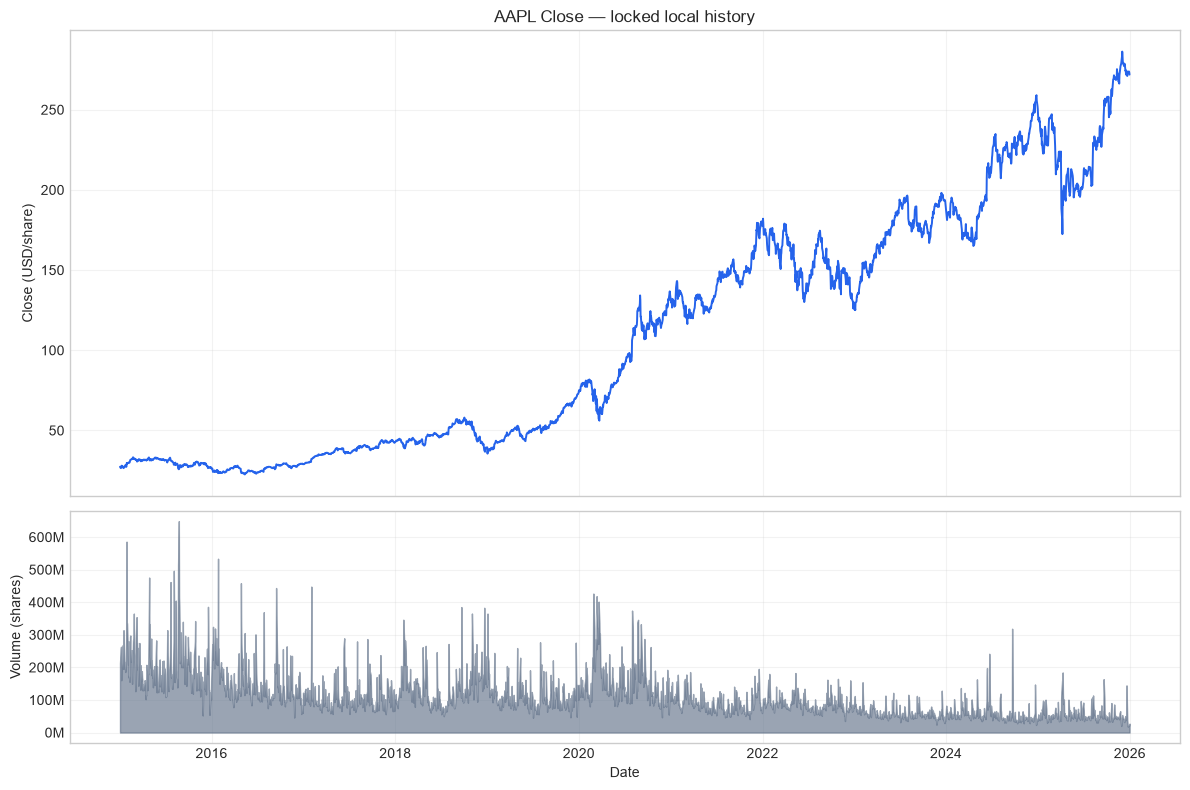

Đã lưu: C:\DATA\assign\A06\results\figures\stock_eda\close_volume_history.png


In [ ]:
if RUN_EXPERIMENTS:
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, height_ratios=[2, 1])

    axes[0].plot(stock["Date"], stock["Close"], color="#2563EB", linewidth=1.4)
    axes[0].set(title="AAPL Close — locked local history", ylabel="Close (USD/share)")
    axes[0].grid(alpha=0.25)

    axes[1].fill_between(stock["Date"], stock["Volume"], color="#64748B", alpha=0.65)
    axes[1].set(xlabel="Date", ylabel="Volume (shares)")
    axes[1].yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1e6:.0f}M"))
    axes[1].grid(alpha=0.25)

    fig.tight_layout()
    output_path = FIGURE_DIR / "close_volume_history.png"
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"Đã lưu: {output_path}")

**Nhận xét:** Close có xu hướng tăng dài hạn nhưng không tăng đều; drawdown và các giai đoạn dao động lớn xuất hiện xuyên suốt. Volume tạo các spikes ngắn hạn và có scale khác hẳn price, củng cố nhu cầu scaling theo feature.

### 5.2 OHLC trong một khoảng thời gian dễ đọc

Toàn bộ 2.766 ngày sẽ làm bốn đường OHLC chồng lấn. Ta chọn Q4/2025 để quan sát khoảng `Low–High` cùng `Open` và `Close` mà không biến chart thành nhiễu. Đây chỉ là zoom EDA, không phải chọn giai đoạn model.


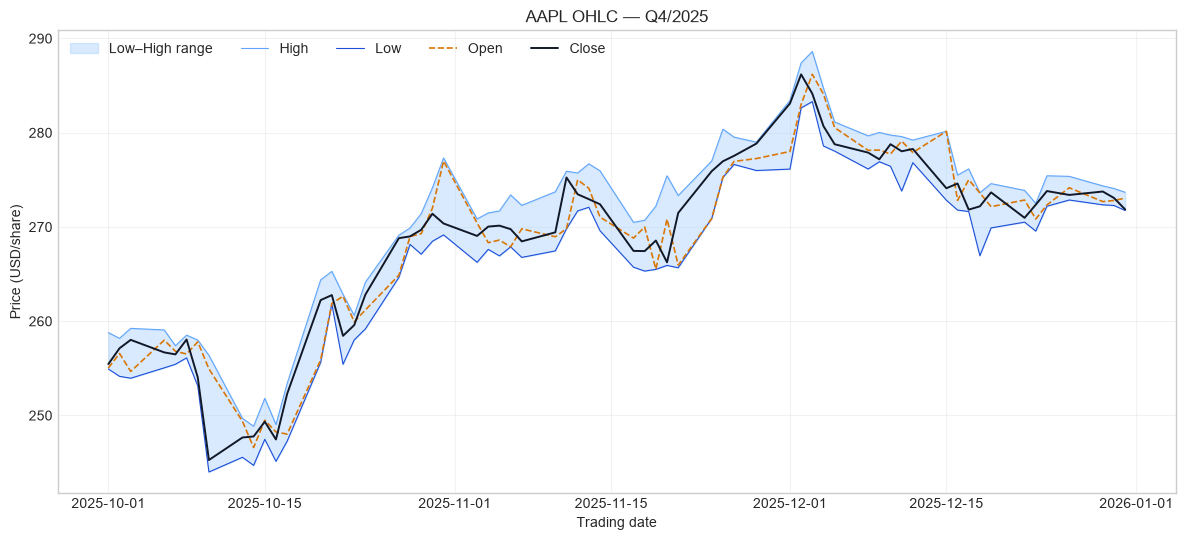

Selected trading rows: 64
Đã lưu: C:\DATA\assign\A06\results\figures\stock_eda\ohlc_q4_2025.png


In [ ]:
if RUN_EXPERIMENTS:
    interval_start = pd.Timestamp("2025-10-01")
    interval_end = pd.Timestamp("2025-12-31")
    ohlc_interval = stock.loc[stock["Date"].between(interval_start, interval_end)].copy()
    assert not ohlc_interval.empty

    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.fill_between(
        ohlc_interval["Date"],
        ohlc_interval["Low"],
        ohlc_interval["High"],
        color="#93C5FD",
        alpha=0.35,
        label="Low–High range",
    )
    ax.plot(
        ohlc_interval["Date"],
        ohlc_interval["High"],
        color="#60A5FA",
        linewidth=0.8,
        label="High",
    )
    ax.plot(
        ohlc_interval["Date"],
        ohlc_interval["Low"],
        color="#1D4ED8",
        linewidth=0.8,
        label="Low",
    )
    ax.plot(
        ohlc_interval["Date"],
        ohlc_interval["Open"],
        color="#D97706",
        linewidth=1.2,
        linestyle="--",
        label="Open",
    )
    ax.plot(
        ohlc_interval["Date"],
        ohlc_interval["Close"],
        color="#111827",
        linewidth=1.4,
        label="Close",
    )
    ax.set(
        title="AAPL OHLC — Q4/2025",
        xlabel="Trading date",
        ylabel="Price (USD/share)",
    )
    ax.legend(ncol=5, loc="upper left")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    output_path = FIGURE_DIR / "ohlc_q4_2025.png"
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"Selected trading rows: {len(ohlc_interval)}")
    print(f"Đã lưu: {output_path}")

**Nhận xét:** `High` và `Low` tạo biên độ nội phiên; `Open` và `Close` nằm trong khoảng này. Khoảng cách và hướng giữa Open–Close thay đổi từng ngày, cho thấy cùng một price level có thể đi kèm động lực nội phiên khác nhau.

### 5.3 Moving averages 7 và 30 periods

Một period ở đây là một **trading observation**, không phải một calendar day. MA(7) phản ứng nhanh hơn; MA(30) mượt hơn và trễ hơn. Hai đường chỉ giúp đọc trend trong EDA và **không phải model features đã khóa**.


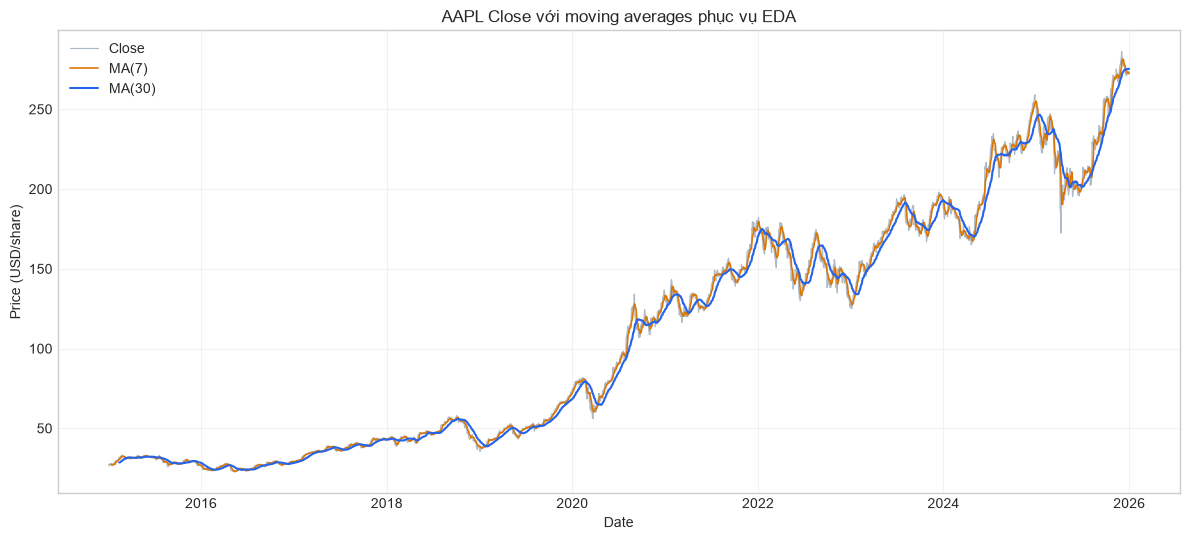

Đã lưu: C:\DATA\assign\A06\results\figures\stock_eda\close_moving_averages.png


In [ ]:
if RUN_EXPERIMENTS:
    stock_eda = stock.copy()
    stock_eda["MA_7"] = stock_eda["Close"].rolling(window=7, min_periods=7).mean()
    stock_eda["MA_30"] = stock_eda["Close"].rolling(window=30, min_periods=30).mean()

    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.plot(
        stock_eda["Date"],
        stock_eda["Close"],
        color="#94A3B8",
        linewidth=0.9,
        alpha=0.75,
        label="Close",
    )
    ax.plot(
        stock_eda["Date"], stock_eda["MA_7"], color="#D97706", linewidth=1.2, label="MA(7)"
    )
    ax.plot(
        stock_eda["Date"],
        stock_eda["MA_30"],
        color="#2563EB",
        linewidth=1.5,
        label="MA(30)",
    )
    ax.set(
        title="AAPL Close với moving averages phục vụ EDA",
        xlabel="Date",
        ylabel="Price (USD/share)",
    )
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    output_path = FIGURE_DIR / "close_moving_averages.png"
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"Đã lưu: {output_path}")

**Nhận xét:** đường trung bình làm rõ xu hướng cục bộ nhưng dùng cả quan sát hiện tại trong chính giá trị MA tại ngày đó. Nếu một feature rolling được thêm ở tương lai, việc căn thời gian phải được kiểm tra chống leakage. Với contract hiện tại, input vẫn chỉ gồm `Open`, `High`, `Low`, `Close`, `Volume`.

### 5.4 Phân phối daily percentage return

Daily return được tính cho EDA bằng:

$$r_t = \left(\frac{Close_t}{Close_{t-1}} - 1\right)\times100\%$$

Return tập trung quanh 0 nhưng có tails, giúp nhìn volatility rõ hơn price level.


,DailyReturnPct
count,"2,765.0000"
mean,0.0996
std,1.8177
min,-12.8647
1%,-4.8073
5%,-2.7201
25%,-0.7395
50%,0.0899
75%,0.9890
95%,2.8372


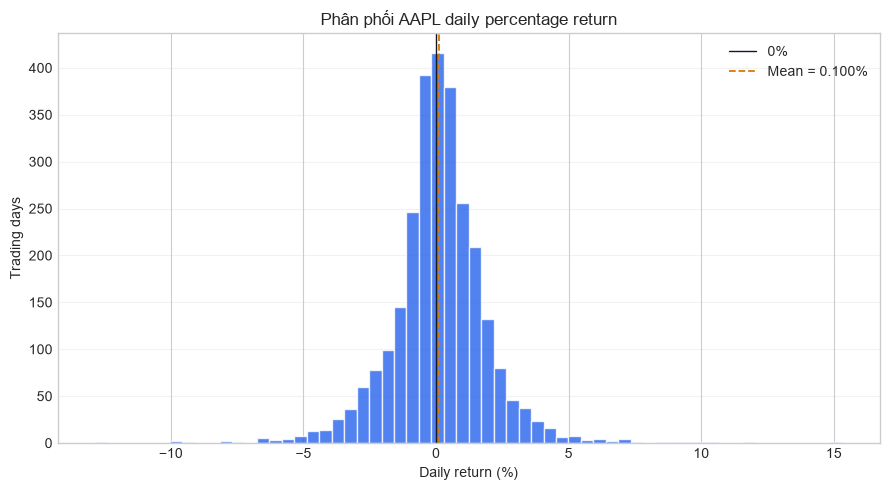

Đã lưu: C:\DATA\assign\A06\results\figures\stock_eda\daily_return_distribution.png


In [ ]:
if RUN_EXPERIMENTS:
    stock_eda["DailyReturnPct"] = stock_eda["Close"].pct_change(fill_method=None) * 100
    daily_returns = stock_eda["DailyReturnPct"].dropna()

    display(
        daily_returns.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
        .rename("DailyReturnPct")
        .to_frame()
    )

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(daily_returns, bins=60, color="#2563EB", alpha=0.8, edgecolor="white")
    ax.axvline(0, color="#111827", linewidth=1.0, label="0%")
    ax.axvline(
        daily_returns.mean(),
        color="#D97706",
        linewidth=1.3,
        linestyle="--",
        label=f"Mean = {daily_returns.mean():.3f}%",
    )
    ax.set(
        title="Phân phối AAPL daily percentage return",
        xlabel="Daily return (%)",
        ylabel="Trading days",
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    output_path = FIGURE_DIR / "daily_return_distribution.png"
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"Đã lưu: {output_path}")

**Nhận xét:** phần lớn returns nằm gần 0, nhưng vẫn có ngày tăng/giảm lớn. Volatility không cố định; các ngày dao động mạnh thường có thể xuất hiện theo cụm. Price level và return trả lời hai câu hỏi khác nhau: price thể hiện scale/trend, return thể hiện thay đổi tương đối.


## 6. Đặc điểm của stock time-series

- **Trend:** price level thay đổi dài hạn, nên mean/variance của `Close` không cố định theo toàn bộ giai đoạn.
- **Volatility:** biên độ biến động thay đổi theo thời gian; yên ắng và biến động mạnh có thể xuất hiện thành cụm.
- **Non-stationary scale:** cùng một thay đổi tuyệt đối có ý nghĩa tương đối khác nhau ở mức giá 30 USD và 250 USD.
- **Temporal dependence:** giá ở các ngày gần nhau thường liên quan mạnh; đó là lý do window 30 trading days có ý nghĩa.
- **Khó dự báo chính xác:** giá phản ứng với thông tin mới, kỳ vọng và regime changes mà OHLCV quá khứ không quan sát đầy đủ. Một model phức tạp không loại bỏ sự bất định này.

Notebook chỉ phân tích dữ liệu lịch sử phục vụ học máy, không đưa ra khuyến nghị mua/bán hay tuyên bố khả năng sinh lời.


## 7. Locked RNN task

Mỗi sample có:

- input shape: **`(30, 5)`**;
- 30 rows là 30 trading days liên tiếp;
- 5 features theo đúng thứ tự: `Open`, `High`, `Low`, `Close`, `Volume`;
- target: `Close` của trading day ngay sau cửa sổ;
- task: **regression** vì target là một giá trị liên tục.

Với batch size 32, tensor input cho RNN có shape `(32, 30, 5)` khi dùng `batch_first=True`.


## 8. Minh họa sliding-window

Window chỉ lấy quá khứ. Với indexing theo row đã sort:

```text
days 1..30  → Close day 31
days 2..31  → Close day 32
days 3..32  → Close day 33
...
```

Code dưới đây chỉ tạo ba preview records và một array shape minh họa; chưa lưu production sequences.


In [ ]:
if RUN_EXPERIMENTS:
    window_preview = []
    for start_index in range(3):
        end_index = start_index + SEQUENCE_LENGTH
        feature_slice = stock.iloc[start_index:end_index]
        target_row = stock.iloc[end_index]

        assert feature_slice["Date"].max() < target_row["Date"]
        window_preview.append(
            {
                "input_rows": f"{start_index + 1}..{end_index}",
                "input_date_start": feature_slice["Date"].iloc[0].date(),
                "input_date_end": feature_slice["Date"].iloc[-1].date(),
                "target_row": end_index + 1,
                "target_date": target_row["Date"].date(),
                "target_close": target_row["Close"],
                "naive_last_close": feature_slice["Close"].iloc[-1],
            }
        )

    first_input = stock.loc[: SEQUENCE_LENGTH - 1, MODEL_FEATURES].to_numpy()
    first_target = stock.loc[SEQUENCE_LENGTH, "Close"]

    display(pd.DataFrame(window_preview))
    print("First input shape:", first_input.shape)
    print("First target scalar:", f"{first_target:.4f}")

,input_rows,input_date_start,input_date_end,target_row,target_date,target_close,naive_last_close
0,1..30,2015-01-02,2015-02-13,31,2015-02-17,31.9575,31.7700
1,2..31,2015-01-05,2015-02-17,32,2015-02-18,32.1800,31.9575
2,3..32,2015-01-06,2015-02-18,33,2015-02-19,32.1125,32.1800


First input shape: (30, 5)
First target scalar: 31.9575


Việc kiểm tra `max(input Date) < target Date` bảo đảm target không nằm trong input. Production pipeline sau này phải gắn mỗi sample với `target_date`, vì split sẽ dựa trên ngày target chứ không dựa trên row ngẫu nhiên.

## 9. Chronological split

`train_test_split(..., shuffle=True)` là sai cho chuỗi thời gian vì nó trộn future samples vào train và past samples vào validation/test. Model có thể học scale hoặc regime từ tương lai, tạo kết quả quá lạc quan.

```text
PAST --------------------------------------------------------> FUTURE
|---------------- TRAIN ----------------|---- VAL ----|---- TEST ----|
                    ~70%                    ~15%          ~15%
```

Sample phải được xếp theo **target date**. Mọi train targets đứng trước validation targets; mọi validation targets đứng trước test targets. Exact boundary dates chưa được khóa trong notebook EDA này và sẽ được xác định khi production windows được tạo.


## 10. Scaling không gây leakage

Scaling cần thiết vì `Volume` có thể ở hàng chục/hàng trăm triệu, trong khi price features ở scale hàng chục/hàng trăm. Nếu không scale, feature lớn về đơn vị có thể chi phối gradient.

Quy trình bắt buộc:

1. tạo windows và gắn `target_date`;
2. split theo thời gian;
3. **fit feature scaler chỉ trên các quan sát thuộc TRAIN**;
4. validation/test chỉ gọi `transform()` bằng scaler đã fit;
5. nếu target được scale, target scaler cũng chỉ fit trên TRAIN targets và predictions phải inverse-transform trước khi báo cáo MAE/RMSE theo đơn vị giá.

Notebook này không fit scaler để tránh biến EDA thành production preprocessing.


## 11. Naive persistence baseline

Baseline đơn giản cho mỗi cửa sổ:

$$\widehat{Close}_{t+1} = Close_t$$

Tức là dự đoán Close ngày kế tiếp gần bằng Close cuối cùng đã quan sát trong 30-day window. Cột `naive_last_close` trong bảng preview minh họa đúng quy tắc này.

Stock prices liên tiếp thường rất gần nhau, nên baseline này có thể có absolute error thấp dù không “hiểu” thị trường. RNN chỉ có ý nghĩa thực nghiệm nếu được đánh giá trên cùng test period và so sánh công bằng với naive baseline; low error tự thân chưa đủ chứng minh giá trị.


## 12. Evaluation metrics

Với $n$ targets thật $y_i$ và predictions $\hat{y}_i$:

**MAE — Mean Absolute Error**

$$MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|$$

- dễ diễn giải theo đơn vị giá sau inverse scaling;
- mỗi sai số đóng góp tuyến tính nên ít nhạy với outlier hơn RMSE.

**RMSE — Root Mean Squared Error**

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}$$

- phạt sai số lớn mạnh hơn MAE;
- vẫn có cùng đơn vị với target.

**$R^2$ — Coefficient of Determination**

$$R^2 = 1 - \frac{\sum_i(y_i-\hat{y}_i)^2}{\sum_i(y_i-\bar{y})^2}$$

- so sánh squared error với baseline dự đoán mean của evaluation set;
- $R^2=1$ là hoàn hảo, $R^2=0$ ngang baseline mean và $R^2<0$ có thể xảy ra khi model tệ hơn baseline mean.

Các metrics phải được tính trên test set chỉ sau khi model selection hoàn tất. Cần báo cáo cả RNN lẫn naive persistence baseline trên cùng targets; không dùng test để chọn hyperparameters hay early stopping.


## Thực hành: 05_PyTorch_Stock_RNN

Code và output lịch sử được giữ để đối chiếu. `RUN_EXPERIMENTS=False` nên không tự tạo split/train/TEST hoặc ghi lại kết quả đã khóa.

**Bản đường dẫn r2.** Notebook gốc và output được giữ trong provenance. Kernel: Python3.11 WSL NumPy/PyTorch. Không Run All pipeline huấn luyện chỉ để xem kết quả đã lưu.


# A06 — PyTorch Vanilla RNN dự báo giá đóng cửa AAPL

Notebook này huấn luyện đúng một mô hình **Vanilla RNN** cho bài toán đã khóa:

$$
\underbrace{30\ \text{ngày giao dịch trước} \times 5\ \text{đặc trưng}}_{X}
\longrightarrow
\underbrace{\text{Close của ngày giao dịch kế tiếp}}_{y}.
$$

Chỉ các artifact đã hoàn tất ở bước tiền xử lý chung được sử dụng. Notebook không đọc lại CSV gốc, không tạo split mới, không fit scaler và không dùng TEST để chọn mô hình. Đây là thực hành kỹ thuật, **không phải khuyến nghị tài chính**.


## 1. Thiết lập tái lập và đường dẫn

`SEED = 42` được áp dụng cho Python, NumPy và PyTorch. Môi trường hiện tại chỉ có CPU; cấu hình nhỏ giúp notebook chạy nhanh và dễ kiểm tra. Các thư mục output được tạo nếu chưa có, nhưng dữ liệu đầu vào chỉ được đọc.


In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    from pathlib import Path
    import hashlib
    import json
    import random
    import sys

    import joblib
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    import torch
    from torch import nn
    from torch.utils.data import DataLoader

    ROOT = Path.cwd().resolve()
    if ROOT.name == "notebooks":
        ROOT = ROOT.parent
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))

    from src.pytorch_stock import (
        StockRNN,
        StockSequenceDataset,
        count_trainable_parameters,
        inverse_transform_targets,
        predict_scaled_targets,
        regression_metrics,
        train_with_early_stopping,
    )

    SEED = 42
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.use_deterministic_algorithms(True)
    torch.set_num_threads(1)

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    PROCESSED_DIR = ROOT / "datasets" / "processed"
    METADATA_PATH = ROOT / "results" / "metrics" / "preprocessing_metadata.json"
    CHECKPOINT_PATH = ROOT / "models" / "pytorch" / "pytorch_stock_rnn_best.pt"
    METRICS_PATH = ROOT / "results" / "metrics" / "pytorch_stock_metrics.json"
    PREDICTIONS_PATH = ROOT / "results" / "predictions" / "pytorch_stock_predictions.csv"
    FIGURE_DIR = ROOT / "results" / "figures" / "pytorch_stock"

    for directory in (
        CHECKPOINT_PATH.parent,
        METRICS_PATH.parent,
        PREDICTIONS_PATH.parent,
        FIGURE_DIR,
    ):
        directory.mkdir(parents=True, exist_ok=True)

    print(f"Project root: {ROOT}")
    print(f"PyTorch: {torch.__version__} | device: {DEVICE} | seed: {SEED}")

Project root: C:\DATA\assign\A06
PyTorch: 2.14.0+cpu | device: cpu | seed: 42


## 2. Nạp đúng artifact đã khóa

Mỗi NPZ phải có `X`, `y`, `y_scaled`, `target_date` và `naive_last_close`. Notebook đối chiếu SHA-256 với `preprocessing_metadata.json`, kiểm tra shape `(samples, 30, 5)`, ngày tăng nghiêm ngặt trong từng split và thứ tự thời gian `TRAIN < validation < TEST`.

Năm đặc trưng theo đúng thứ tự là `Open`, `High`, `Low`, `Close`, `Volume`. `target_date` chỉ là metadata để truy vết và vẽ biểu đồ; nó không đi vào mô hình.


In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    def sha256(path: Path) -> str:
        return hashlib.sha256(path.read_bytes()).hexdigest()


    metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
    stock_meta = metadata["stock"]
    assert metadata["seed"] == SEED
    assert stock_meta["sequence_length"] == 30
    assert stock_meta["feature_names"] == ["Open", "High", "Low", "Close", "Volume"]

    artifacts = {}
    artifact_hashes = {}
    required_keys = {"X", "y", "y_scaled", "target_date", "naive_last_close"}

    for split in ("train", "val", "test"):
        info = stock_meta["artifacts"][split]
        path = ROOT / info["path"]
        actual_hash = sha256(path)
        assert actual_hash == info["sha256"], f"Checksum sai: {path}"
        with np.load(path) as loaded:
            assert set(loaded.files) == required_keys
            artifacts[split] = {name: loaded[name].copy() for name in loaded.files}
        data = artifacts[split]
        assert data["X"].shape[1:] == (30, 5)
        assert data["y"].shape == data["y_scaled"].shape == data["target_date"].shape
        assert len(data["X"]) == len(data["y"])
        assert np.isfinite(data["X"]).all()
        assert np.isfinite(data["y"]).all()
        assert np.isfinite(data["y_scaled"]).all()
        assert np.all(data["target_date"][1:] > data["target_date"][:-1])
        artifact_hashes[split] = actual_hash

    assert artifacts["train"]["target_date"][-1] < artifacts["val"]["target_date"][0]
    assert artifacts["val"]["target_date"][-1] < artifacts["test"]["target_date"][0]

    split_summary = pd.DataFrame(
        [
            {
                "split": split.upper(),
                "X shape": str(data["X"].shape),
                "y shape": str(data["y"].shape),
                "ngày đầu": str(data["target_date"][0]),
                "ngày cuối": str(data["target_date"][-1]),
            }
            for split, data in artifacts.items()
        ]
    )
    split_summary

,split,X shape,y shape,ngày đầu,ngày cuối
0,TRAIN,"(1915, 30, 5)","(1915,)",2015-02-17,2022-09-22
1,VAL,"(411, 30, 5)","(411,)",2022-09-23,2024-05-13
2,TEST,"(410, 30, 5)","(410,)",2024-05-14,2025-12-31


## 3. Regression, target scaling và đơn vị đánh giá

Đây là **regression** vì đầu ra là một giá trị liên tục (giá `Close`), khác classification vốn dự đoán nhãn rời rạc. Pipeline chung đã chuẩn hóa cả đầu vào và target bằng thống kê từ **chỉ TRAIN**. Mô hình học `y_scaled`; vì vậy `MSELoss` trong quá trình huấn luyện nằm trong **không gian chuẩn hóa**, không phải USD².

Sau khi chọn checkpoint bằng validation loss, dự đoán TEST sẽ được `inverse_transform` bằng target scaler đã khóa. Chỉ khi đó MAE và RMSE mới có đơn vị USD. Không được fit lại scaler trên validation hay TEST.


In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    target_scaler_info = stock_meta["target_scaler"]
    target_scaler_path = ROOT / target_scaler_info["path"]
    assert sha256(target_scaler_path) == target_scaler_info["sha256"]
    target_scaler = joblib.load(target_scaler_path)
    assert int(target_scaler.n_samples_seen_) == len(artifacts["train"]["y"])

    for split, data in artifacts.items():
        restored = inverse_transform_targets(target_scaler, data["y_scaled"])
        np.testing.assert_allclose(restored, data["y"], rtol=1e-5, atol=1e-4)

    print("Target scaler:", type(target_scaler).__name__)
    print("Fit scope:", target_scaler_info["fit_scope"])
    print(f"TRAIN mean={target_scaler.mean_[0]:.6f}, scale={target_scaler.scale_[0]:.6f}")
    print("Inverse-transform khớp raw y ở cả ba split.")

Target scaler: StandardScaler
Fit scope: TRAIN y only
TRAIN mean=71.203423, scale=48.037949
Inverse-transform khớp raw y ở cả ba split.


## 4. Dataset và DataLoader

`StockSequenceDataset` ánh xạ mỗi mẫu thành tensor `X` có shape `(30, 5)` và một target vô hướng đã scale. Khi ghép batch, mô hình nhận `(batch_size, 30, 5)`.

`DataLoader` chia dữ liệu thành mini-batch. Chỉ TRAIN dùng `shuffle=True` để thay đổi thứ tự cập nhật gradient; validation và TEST giữ `shuffle=False`. Việc shuffle các mẫu TRAIN không làm thay đổi thứ tự 30 time step bên trong từng sequence.


In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    BATCH_SIZE = 64
    generator = torch.Generator().manual_seed(SEED)

    datasets = {
        split: StockSequenceDataset(data["X"], data["y_scaled"])
        for split, data in artifacts.items()
    }
    train_loader = DataLoader(
        datasets["train"], batch_size=BATCH_SIZE, shuffle=True, generator=generator
    )
    validation_loader = DataLoader(datasets["val"], batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(datasets["test"], batch_size=BATCH_SIZE, shuffle=False)

    batch_x, batch_y = next(iter(train_loader))
    print("Một TRAIN batch:", tuple(batch_x.shape), tuple(batch_y.shape))
    print(
        "Số batch TRAIN / validation / TEST:",
        len(train_loader),
        len(validation_loader),
        len(test_loader),
    )

Một TRAIN batch: (64, 30, 5) (64,)
Số batch TRAIN / validation / TEST: 30 7 7


## 5. Kiến trúc Vanilla RNN

Với `batch_first=True`, RNN đọc lần lượt 30 vector đặc trưng. Hidden state được cập nhật qua thời gian:

$$h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b).$$

`h_n[-1]` là hidden state sau ngày thứ 30: một biểu diễn cô đọng của cửa sổ lịch sử. Lớp `Linear(64, 1)` biến biểu diễn này thành một giá trị target đã scale. Không có Sigmoid vì regression không cần ép đầu ra vào `[0, 1]`; mô hình chính cũng không được thay bằng LSTM/GRU.


In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    HIDDEN_SIZE = 64
    model = StockRNN(input_size=5, hidden_size=HIDDEN_SIZE, num_layers=1).to(DEVICE)
    parameter_count = count_trainable_parameters(model)

    with torch.inference_mode():
        demo_output = model(batch_x[:4].to(DEVICE))

    print(model)
    print("Demo input:", tuple(batch_x[:4].shape), "-> output:", tuple(demo_output.shape))
    print("Trainable parameters:", f"{parameter_count:,}")
    assert isinstance(model.rnn, nn.RNN)
    assert model.rnn.batch_first is True
    assert parameter_count == 4609

StockRNN(
  (rnn): RNN(5, 64, batch_first=True)
  (regressor): Linear(in_features=64, out_features=1, bias=True)
)
Demo input: (4, 30, 5) -> output: (4,)
Trainable parameters: 4,609


## 6. Huấn luyện bằng MSE và early stopping

`MSELoss` lấy trung bình bình phương sai số trong không gian target đã scale, nên phạt sai số lớn mạnh hơn sai số nhỏ. Adam cập nhật trọng số từ gradient của TRAIN. Sau mỗi epoch, validation loss được tính mà không cập nhật trọng số.

Checkpoint được ghi khi validation loss đạt mức thấp nhất mới. `patience=5` dừng khi không có cải thiện đủ ý nghĩa trong năm epoch liên tiếp; sau cùng mô hình luôn khôi phục checkpoint có **validation loss thô thấp nhất**. TEST hoàn toàn chưa được xem trong bước này.


In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    MAX_EPOCHS = 30
    PATIENCE = 5
    LEARNING_RATE = 1e-3

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    training_result = train_with_early_stopping(
        model=model,
        train_loader=train_loader,
        validation_loader=validation_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=DEVICE,
        checkpoint_path=CHECKPOINT_PATH,
        max_epochs=MAX_EPOCHS,
        patience=PATIENCE,
        min_delta=1e-4,
        gradient_clip_norm=1.0,
        seed=SEED,
        verbose=True,
    )

    print(
        f"Đã chạy {training_result['epochs_ran']} epoch; "
        f"best epoch={training_result['best_epoch']}; "
        f"best validation MSE (scaled)={training_result['best_validation_loss']:.6f}; "
        f"thời gian={training_result['training_duration_seconds']:.2f}s"
    )

Epoch 01/30 | train=0.178107 | val=0.146794 *

Epoch 02/30 | train=0.006747 | val=0.030797 *


Epoch 03/30 | train=0.003186 | val=0.029456 *


Epoch 04/30 | train=0.002544 | val=0.018763 *


Epoch 05/30 | train=0.002299 | val=0.013108 *


Epoch 06/30 | train=0.002124 | val=0.010180 *


... (4 outputs left out)

Epoch 11/30 | train=0.001949 | val=0.011187


Epoch 12/30 | train=0.002150 | val=0.007103


Epoch 13/30 | train=0.002035 | val=0.006706


Epoch 14/30 | train=0.001857 | val=0.008180
Early stopping at epoch 14; best epoch = 9.
Đã chạy 14 epoch; best epoch=9; best validation MSE (scaled)=0.006525; thời gian=5.61s


## 7. Learning curve trong training space

Hai đường dưới đây đều là MSE của target đã scale. Chúng giúp theo dõi tối ưu hóa và khoảng cách tổng quát hóa, nhưng **không phải** sai số giá bằng USD.


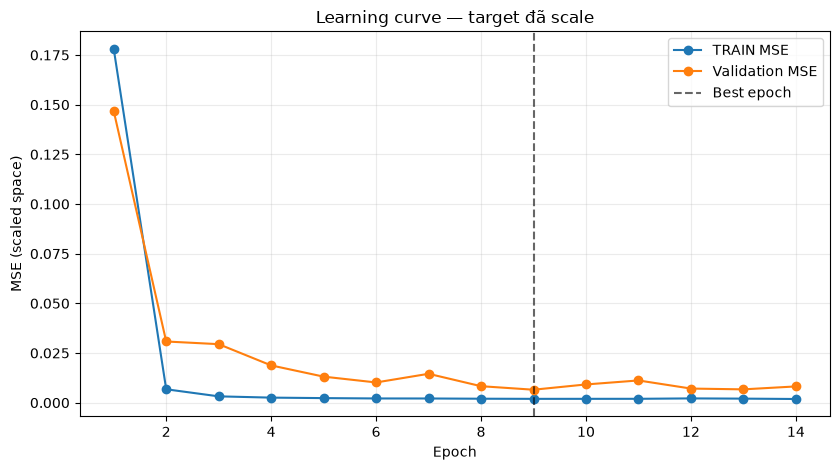

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    epochs = np.arange(1, training_result["epochs_ran"] + 1)
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    ax.plot(epochs, training_result["history"]["train_loss"], marker="o", label="TRAIN MSE")
    ax.plot(
        epochs,
        training_result["history"]["validation_loss"],
        marker="o",
        label="Validation MSE",
    )
    ax.axvline(
        training_result["best_epoch"],
        color="black",
        linestyle="--",
        alpha=0.6,
        label="Best epoch",
    )
    ax.set(
        title="Learning curve — target đã scale",
        xlabel="Epoch",
        ylabel="MSE (scaled space)",
    )
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    loss_figure_path = FIGURE_DIR / "training_validation_loss.png"
    fig.savefig(loss_figure_path, dpi=160, bbox_inches="tight")
    plt.show()

## 8. Đánh giá TEST một lần và naive baseline

Sau khi validation đã chọn xong mô hình, checkpoint tốt nhất được đánh giá **một lần** trên TEST. Dự đoán RNN được inverse-transform về giá `Close` thực.

Baseline persistence dùng cùng đúng các mẫu TEST:

$$\widehat{Close}_{t+1}^{naive} = Close_t,$$

tức lấy `Close` cuối cùng trong cửa sổ 30 ngày làm dự đoán ngày kế tiếp. Baseline rất quan trọng: giá cổ phiếu thường thay đổi từng ngày ít hơn mức giá tuyệt đối, nên một mô hình có MAE nhỏ vẫn có thể kém quy tắc đơn giản này.

- **MAE:** độ lớn sai số tuyệt đối trung bình, dễ đọc theo USD.
- **RMSE:** căn của MSE, cũng theo USD nhưng nhạy hơn với sai số lớn.
- **R²:** so với dự đoán hằng bằng trung bình TEST; 1 là hoàn hảo, 0 tương đương mốc đó, và có thể âm. R² không trực tiếp so với naive baseline, vì vậy phải nhìn cả hai hàng metric.


In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    test_scaled_true, test_scaled_prediction = predict_scaled_targets(
        model, test_loader, device=DEVICE
    )
    test_actual = artifacts["test"]["y"].astype(np.float64)
    test_prediction = inverse_transform_targets(target_scaler, test_scaled_prediction)
    test_true_restored = inverse_transform_targets(target_scaler, test_scaled_true)
    test_naive = artifacts["test"]["naive_last_close"].astype(np.float64)

    np.testing.assert_allclose(test_true_restored, test_actual, rtol=1e-5, atol=1e-4)
    rnn_metrics = regression_metrics(test_actual, test_prediction)
    naive_metrics = regression_metrics(test_actual, test_naive)

    metric_table = pd.DataFrame(
        [
            {
                "Mô hình": "Vanilla RNN",
                "MAE (USD)": rnn_metrics["mae"],
                "RMSE (USD)": rnn_metrics["rmse"],
                "R²": rnn_metrics["r2"],
            },
            {
                "Mô hình": "Naive: last Close",
                "MAE (USD)": naive_metrics["mae"],
                "RMSE (USD)": naive_metrics["rmse"],
                "R²": naive_metrics["r2"],
            },
        ]
    ).set_index("Mô hình")
    metric_table.round(4)

,MAE (USD),RMSE (USD),R²
Mô hình,,,
Vanilla RNN,20.3393,23.5788,-0.0269
Naive: last Close,2.6177,3.8789,0.9722


In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    if rnn_metrics["rmse"] < naive_metrics["rmse"]:
        comparison_message = (
            "RNN có RMSE thấp hơn naive trên TEST trong lần chạy đã khóa này."
        )
    elif rnn_metrics["rmse"] > naive_metrics["rmse"]:
        comparison_message = "Naive có RMSE thấp hơn RNN trên TEST; không có bằng chứng để tuyên bố RNN tốt hơn baseline."
    else:
        comparison_message = (
            "RNN và naive có RMSE bằng nhau trong độ chính xác số hiện tại."
        )
    print(comparison_message)

Naive có RMSE thấp hơn RNN trên TEST; không có bằng chứng để tuyên bố RNN tốt hơn baseline.


## 9. Lưu prediction và metrics có thể truy vết

CSV giữ một hàng cho mỗi ngày mục tiêu theo đúng thứ tự thời gian. JSON ghi kiến trúc, quá trình huấn luyện, metric thực trên thang giá, metric baseline, checksum đầu vào và thông tin scaling. `target_date` không bị dùng như feature.


In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    test_dates = pd.to_datetime(artifacts["test"]["target_date"].astype(str))
    predictions = pd.DataFrame(
        {
            "target_date": test_dates.strftime("%Y-%m-%d"),
            "actual_close": test_actual,
            "predicted_close": test_prediction,
            "naive_close": test_naive,
        }
    )
    assert predictions["target_date"].is_monotonic_increasing
    assert not predictions.isna().any().any()
    predictions.to_csv(PREDICTIONS_PATH, index=False)

    metrics_payload = {
        "task": "30 previous trading days x 5 features -> next trading day's Close",
        "framework": "PyTorch",
        "architecture": {
            "recurrent_layer": "torch.nn.RNN",
            "input_size": 5,
            "hidden_size": HIDDEN_SIZE,
            "num_layers": 1,
            "batch_first": True,
            "nonlinearity": "tanh",
            "head": "Linear(64, 1)",
        },
        "parameter_count": parameter_count,
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "loss": "MSELoss on scaled target",
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "epochs": training_result["epochs_ran"],
        "epochs_actually_run": training_result["epochs_ran"],
        "best_epoch": training_result["best_epoch"],
        "best_validation_loss": training_result["best_validation_loss"],
        "best_validation_loss_space": "standardized target",
        "device": str(DEVICE),
        "training_duration_seconds": training_result["training_duration_seconds"],
        "MAE": rnn_metrics["mae"],
        "RMSE": rnn_metrics["rmse"],
        "R2": rnn_metrics["r2"],
        "naive_MAE": naive_metrics["mae"],
        "naive_RMSE": naive_metrics["rmse"],
        "naive_R2": naive_metrics["r2"],
        "test_metrics_real_scale": rnn_metrics,
        "naive_test_metrics_real_scale": naive_metrics,
        "real_scale_units": {"mae": "USD", "rmse": "USD", "r2": "unitless"},
        "test_evaluation_count": 1,
        "test_samples": len(predictions),
        "target_date_range": {
            "min": predictions["target_date"].iloc[0],
            "max": predictions["target_date"].iloc[-1],
        },
        "target_scaling": {
            "type": type(target_scaler).__name__,
            "fit_scope": target_scaler_info["fit_scope"],
            "path": target_scaler_info["path"],
            "sha256": target_scaler_info["sha256"],
            "inverse_transformed_for_final_metrics": True,
        },
        "input_artifact_sha256": artifact_hashes,
        "checkpoint": str(CHECKPOINT_PATH.relative_to(ROOT)).replace("\\", "/"),
        "predictions": str(PREDICTIONS_PATH.relative_to(ROOT)).replace("\\", "/"),
        "comparison": comparison_message,
    }
    METRICS_PATH.write_text(
        json.dumps(metrics_payload, ensure_ascii=False, indent=2), encoding="utf-8"
    )

    print(
        f"Đã lưu {len(predictions):,} predictions -> {PREDICTIONS_PATH.relative_to(ROOT)}"
    )
    print(f"Đã lưu metrics -> {METRICS_PATH.relative_to(ROOT)}")
    predictions.head()

Đã lưu 410 predictions -> results\predictions\pytorch_stock_predictions.csv
Đã lưu metrics -> results\metrics\pytorch_stock_metrics.json


,target_date,actual_close,predicted_close,naive_close
0,2024-05-14,187.429993,182.216207,186.279999
1,2024-05-15,189.720001,183.601980,187.429993
2,2024-05-16,189.839996,184.804914,189.720001
3,2024-05-17,189.869995,185.953275,189.839996
4,2024-05-20,191.039993,186.191855,189.869995


## 10. Actual và predicted theo thời gian

Đồ thị nối các ngày TEST theo thứ tự thực, không xáo trộn trục thời gian. Cả RNN và naive đều được đặt cạnh giá thật trên cùng thang USD; biểu đồ chỉ mô tả kết quả ngoài mẫu của khoảng TEST đã khóa.


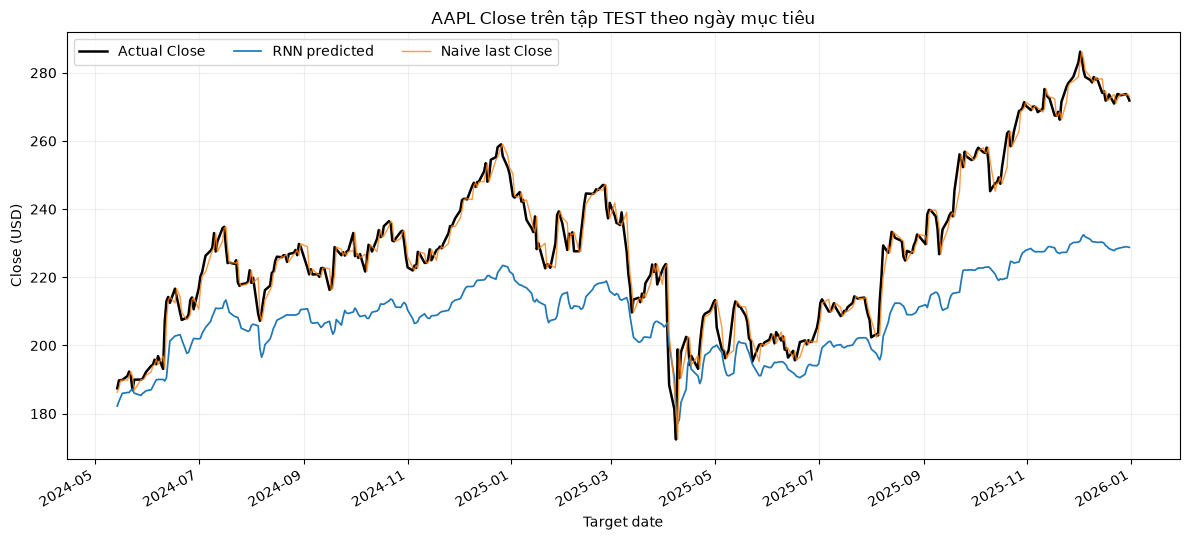

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.plot(test_dates, test_actual, color="black", linewidth=1.8, label="Actual Close")
    ax.plot(
        test_dates, test_prediction, color="#1f77b4", linewidth=1.25, label="RNN predicted"
    )
    ax.plot(
        test_dates,
        test_naive,
        color="#ff7f0e",
        linewidth=1.0,
        alpha=0.8,
        label="Naive last Close",
    )
    ax.set(
        title="AAPL Close trên tập TEST theo ngày mục tiêu",
        xlabel="Target date",
        ylabel="Close (USD)",
    )
    ax.grid(alpha=0.2)
    ax.legend(ncol=3)
    fig.autofmt_xdate()
    fig.tight_layout()
    prediction_figure_path = FIGURE_DIR / "test_actual_vs_predicted.png"
    fig.savefig(prediction_figure_path, dpi=160, bbox_inches="tight")
    plt.show()

## 11. So sánh RNN với baseline

MAE và RMSE có cùng đơn vị USD nên có thể so sánh trực tiếp. R² được tách sang panel riêng vì không có đơn vị và có thang đo khác. Chiều cao cột chỉ phản ánh TEST đã khóa, không chứng minh khả năng sinh lời hay dự báo cho giai đoạn tương lai khác.


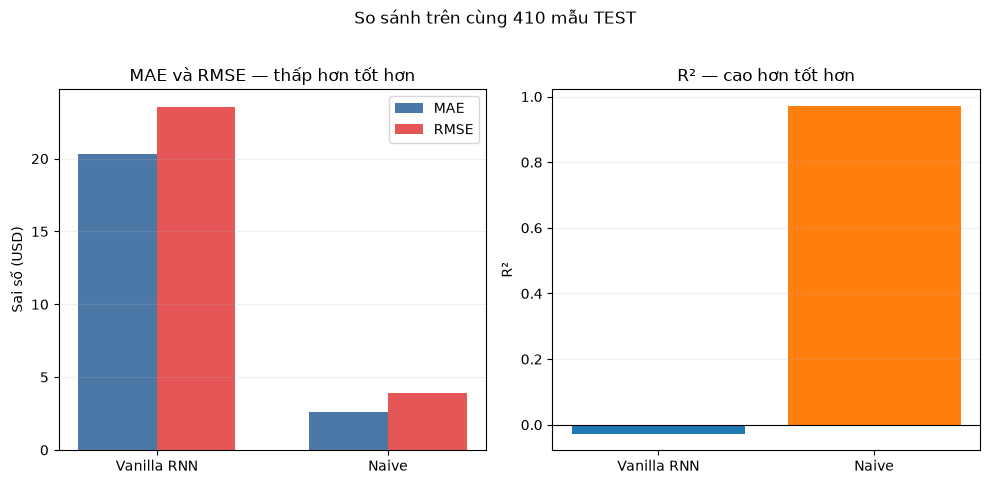

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    labels = ["Vanilla RNN", "Naive"]
    colors = ["#1f77b4", "#ff7f0e"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.7))

    x = np.arange(2)
    width = 0.34
    axes[0].bar(
        x - width / 2,
        [rnn_metrics["mae"], naive_metrics["mae"]],
        width,
        label="MAE",
        color="#4c78a8",
    )
    axes[0].bar(
        x + width / 2,
        [rnn_metrics["rmse"], naive_metrics["rmse"]],
        width,
        label="RMSE",
        color="#e45756",
    )
    axes[0].set_xticks(x, labels)
    axes[0].set_ylabel("Sai số (USD)")
    axes[0].set_title("MAE và RMSE — thấp hơn tốt hơn")
    axes[0].legend()
    axes[0].grid(axis="y", alpha=0.2)

    axes[1].bar(labels, [rnn_metrics["r2"], naive_metrics["r2"]], color=colors)
    axes[1].axhline(0, color="black", linewidth=0.8)
    axes[1].set_ylabel("R²")
    axes[1].set_title("R² — cao hơn tốt hơn")
    axes[1].grid(axis="y", alpha=0.2)

    fig.suptitle("So sánh trên cùng 410 mẫu TEST", y=1.02)
    fig.tight_layout()
    comparison_figure_path = FIGURE_DIR / "rnn_vs_naive_metrics.png"
    fig.savefig(comparison_figure_path, dpi=160, bbox_inches="tight")
    plt.show()

## 12. Kiểm tra artifact đầu ra

Kiểm tra cuối xác nhận checkpoint tồn tại, CSV có đúng schema và ngày tăng nghiêm ngặt, JSON có đủ metric bắt buộc, hình đã được ghi, và ba NPZ đầu vào vẫn giữ nguyên checksum. Đây là lớp kiểm tra chống output thiếu hoặc vô tình thay đổi dữ liệu dùng chung.


In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'torch':
    expected_columns = ["target_date", "actual_close", "predicted_close", "naive_close"]
    assert CHECKPOINT_PATH.is_file()
    assert METRICS_PATH.is_file()
    assert PREDICTIONS_PATH.is_file()
    assert predictions.columns.tolist() == expected_columns
    assert len(predictions) == len(artifacts["test"]["y"]) == 410
    assert pd.to_datetime(predictions["target_date"]).is_monotonic_increasing
    assert all(
        path.is_file()
        for path in (loss_figure_path, prediction_figure_path, comparison_figure_path)
    )

    saved_metrics = json.loads(METRICS_PATH.read_text(encoding="utf-8"))
    for key in ("MAE", "RMSE", "R2", "naive_MAE", "naive_RMSE", "naive_R2"):
        assert np.isfinite(saved_metrics[key])
    for split, expected_hash in artifact_hashes.items():
        input_path = ROOT / stock_meta["artifacts"][split]["path"]
        assert sha256(input_path) == expected_hash

    print("PASS — notebook chạy đầy đủ, output hợp lệ, input artifact không đổi.")
    print("Figures:", sorted(path.name for path in FIGURE_DIR.glob("*.png")))

PASS — notebook chạy đầy đủ, output hợp lệ, input artifact không đổi.
Figures: ['rnn_vs_naive_metrics.png', 'test_actual_vs_predicted.png', 'training_validation_loss.png']


## 13. Kết luận và giới hạn

- Bài toán là regression: 30 ngày × 5 đặc trưng → một `Close` liên tục của ngày kế tiếp.
- Vanilla RNN dùng hidden state cuối để tóm tắt chuỗi; `Linear(64, 1)` tạo dự đoán.
- MSE huấn luyện nằm trong không gian đã scale; MAE/RMSE cuối cùng chỉ được tính sau inverse scaling về USD.
- Validation loss quyết định checkpoint và thời điểm dừng; TEST không tham gia lựa chọn mô hình.
- Naive last-Close là mốc bắt buộc. Kết luận RNN tốt hơn hay kém hơn phải dựa vào bảng metric thực, không dựa vào độ phức tạp của mô hình.
- Giá cổ phiếu chịu tác động của tin tức, kỳ vọng, thanh khoản và thay đổi chế độ thị trường mà năm biến OHLCV quá khứ không thể mô tả đầy đủ. Một split lịch sử đơn lẻ cũng không bảo đảm kết quả sẽ lặp lại trong tương lai.

Notebook này chỉ là baseline học thuật cho A06 và **không đưa ra khuyến nghị đầu tư**.


## Thực hành: 07_Keras_Stock_RNN

Code và output lịch sử được giữ để đối chiếu. `RUN_EXPERIMENTS=False` nên không tự tạo split/train/TEST hoặc ghi lại kết quả đã khóa.

**Bản đường dẫn r2.** Notebook gốc và output được giữ trong provenance. Kernel: Python3.11 WSL TensorFlow/Keras. Không Run All pipeline huấn luyện chỉ để xem kết quả đã lưu.


# A06 — Keras Vanilla RNN dự báo giá đóng cửa AAPL

Notebook này huấn luyện Keras baseline cho đúng bài toán đã khóa:

$$
\underbrace{30\ \text{ngày giao dịch trước} \times 5\ \text{đặc trưng}}_{X}
\longrightarrow
\underbrace{\text{Close của ngày giao dịch kế tiếp}}_{y}.
$$

Keras dùng chính các artifact, split, scalers, target và naive baseline của thí nghiệm PyTorch. Notebook không đọc lại CSV gốc, không tạo cửa sổ mới, không chia lại dữ liệu và không fit scaler. Nội dung chỉ phục vụ học thuật, **không phải khuyến nghị tài chính**.

## 1. Thiết lập tái lập

`SEED = 42` được áp dụng cho Python, NumPy và TensorFlow/Keras. Deterministic operations được bật khi runtime hỗ trợ; điều này giảm dao động trong cùng môi trường nhưng không đảm bảo bit-for-bit giữa các framework hoặc phần cứng khác nhau.

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'keras':
    from pathlib import Path
    import hashlib
    import json
    import os
    import random
    import sys
    import time

    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
    os.environ["TF_DETERMINISTIC_OPS"] = "1"

    import joblib
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    import tensorflow as tf
    from tensorflow import keras

    ROOT = Path.cwd().resolve()
    if ROOT.name == "notebooks":
        ROOT = ROOT.parent
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))

    from src.keras_stock import (
        build_callbacks,
        build_stock_rnn,
        inverse_transform_targets,
        regression_metrics,
        validate_stock_arrays,
    )

    SEED = 42
    random.seed(SEED)
    np.random.seed(SEED)
    keras.utils.set_random_seed(SEED)
    tf.config.experimental.enable_op_determinism()

    METADATA_PATH = ROOT / "results" / "metrics" / "preprocessing_metadata.json"
    PYTORCH_METRICS_PATH = ROOT / "results" / "metrics" / "pytorch_stock_metrics.json"
    MODEL_PATH = ROOT / "models" / "keras" / "keras_stock_rnn_best.keras"
    METRICS_PATH = ROOT / "results" / "metrics" / "keras_stock_metrics.json"
    PREDICTIONS_PATH = ROOT / "results" / "predictions" / "keras_stock_predictions.csv"
    FIGURE_DIR = ROOT / "results" / "figures" / "keras_stock"

    for directory in (MODEL_PATH.parent, METRICS_PATH.parent, PREDICTIONS_PATH.parent, FIGURE_DIR):
        directory.mkdir(parents=True, exist_ok=True)

    device_label = "GPU" if tf.config.list_physical_devices("GPU") else "CPU"
    print(f"Project root: {ROOT}")
    print(f"TensorFlow: {tf.__version__} | Keras: {keras.__version__} | device: {device_label} | seed: {SEED}")

Project root: C:\DATA\assign\A06
TensorFlow: 2.21.0 | Keras: 3.15.1 | device: CPU | seed: 42


## 2. Nạp đúng artifact dùng chung

Mỗi NPZ phải chứa `X`, raw `y`, `y_scaled`, `target_date` và `naive_last_close`. Notebook kiểm tra SHA-256, shape `(samples, 30, 5)`, ngày tăng nghiêm ngặt và thứ tự `TRAIN < validation < TEST`.

Năm feature giữ nguyên thứ tự `Open`, `High`, `Low`, `Close`, `Volume`. `target_date` chỉ là metadata để truy vết và vẽ biểu đồ; nó không đi vào mô hình.

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'keras':
    def sha256(path: Path) -> str:
        return hashlib.sha256(path.read_bytes()).hexdigest()


    metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
    pytorch_metrics = json.loads(PYTORCH_METRICS_PATH.read_text(encoding="utf-8"))
    stock_meta = metadata["stock"]

    assert metadata["seed"] == pytorch_metrics["seed"] == SEED
    assert stock_meta["sequence_length"] == 30
    assert stock_meta["feature_names"] == ["Open", "High", "Low", "Close", "Volume"]
    assert pytorch_metrics["architecture"]["hidden_size"] == 64

    required_keys = {"X", "y", "y_scaled", "target_date", "naive_last_close"}
    artifacts = {}
    artifact_hashes = {}
    for split in ("train", "val", "test"):
        info = stock_meta["artifacts"][split]
        path = ROOT / info["path"]
        actual_hash = sha256(path)
        assert actual_hash == info["sha256"], f"Checksum sai: {path}"
        with np.load(path) as loaded:
            assert set(loaded.files) == required_keys
            artifacts[split] = {name: loaded[name].copy() for name in loaded.files}
        data = artifacts[split]
        validate_stock_arrays(data["X"], data["y_scaled"])
        assert data["y"].shape == data["target_date"].shape == data["naive_last_close"].shape
        assert np.all(data["target_date"][1:] > data["target_date"][:-1])
        artifact_hashes[split] = actual_hash

    assert artifacts["train"]["target_date"][-1] < artifacts["val"]["target_date"][0]
    assert artifacts["val"]["target_date"][-1] < artifacts["test"]["target_date"][0]

    pd.DataFrame(
        [
            {
                "split": split.upper(),
                "X shape": str(data["X"].shape),
                "y shape": str(data["y"].shape),
                "ngày đầu": str(data["target_date"][0]),
                "ngày cuối": str(data["target_date"][-1]),
            }
            for split, data in artifacts.items()
        ]
    ).set_index("split")

,X shape,y shape,ngày đầu,ngày cuối
split,,,,
TRAIN,"(1915, 30, 5)","(1915,)",2015-02-17,2022-09-22
VAL,"(411, 30, 5)","(411,)",2022-09-23,2024-05-13
TEST,"(410, 30, 5)","(410,)",2024-05-14,2025-12-31


## 3. Regression, scaling và thang đo thực

Đây là **regression** vì đầu ra là giá `Close` liên tục. Pipeline chung đã chuẩn hóa input và target bằng thống kê chỉ từ TRAIN. Mô hình học `y_scaled`, nên MSE trong `fit()` nằm trong **không gian chuẩn hóa**, không phải USD².

Target scaler sau đây là đúng scaler PyTorch đã dùng. Validation và TEST không fit lại scaler. Sau khi validation chọn xong mô hình, prediction TEST mới được inverse-transform về giá thực để tính MAE, RMSE và R².

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'keras':
    target_scaler_info = stock_meta["target_scaler"]
    target_scaler_path = ROOT / target_scaler_info["path"]
    assert sha256(target_scaler_path) == target_scaler_info["sha256"]
    assert target_scaler_info["sha256"] == pytorch_metrics["target_scaling"]["sha256"]
    target_scaler = joblib.load(target_scaler_path)
    assert int(target_scaler.n_samples_seen_) == len(artifacts["train"]["y"])

    for split, data in artifacts.items():
        restored = inverse_transform_targets(target_scaler, data["y_scaled"])
        np.testing.assert_allclose(restored, data["y"], rtol=1e-5, atol=1e-4)

    print("Target scaler:", type(target_scaler).__name__)
    print("Fit scope:", target_scaler_info["fit_scope"])
    print(f"TRAIN mean={target_scaler.mean_[0]:.6f}, scale={target_scaler.scale_[0]:.6f}")
    print("Inverse-transform khớp raw y ở cả ba split.")

Target scaler: StandardScaler
Fit scope: TRAIN y only
TRAIN mean=71.203423, scale=48.037949
Inverse-transform khớp raw y ở cả ba split.


## 4. `SimpleRNN` và `Dense` tuyến tính

`SimpleRNN(64)` đọc 30 time steps, mỗi time step có 5 feature. Với `return_sequences=False` mặc định, layer trả về hidden state cuối gồm 64 giá trị — bản tóm tắt học được của cửa sổ lịch sử.

`Dense(1, activation="linear")` ánh xạ hidden state thành một số thực. Không dùng sigmoid vì giá trị regression không bị giới hạn trong `[0,1]`.

| PyTorch | Keras | Vai trò |
|---|---|---|
| `nn.RNN(5, 64, batch_first=True)` | `SimpleRNN(64, input_shape=(30, 5))` | Xử lý chuỗi và lấy hidden state cuối |
| `Linear(64, 1)` | `Dense(1, activation="linear")` | Dự đoán một target đã scale |

Số tham số hơi khác vì cách hai framework tổ chức bias RNN khác nhau; ý định kiến trúc vẫn tương đương.

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'keras':
    HIDDEN_UNITS = 64
    LEARNING_RATE = 1e-3
    model = build_stock_rnn(
        input_shape=(30, 5),
        hidden_units=HIDDEN_UNITS,
        learning_rate=LEARNING_RATE,
    )
    parameter_count = model.count_params()
    model.summary()

    demo_output = model(artifacts["train"]["X"][:4], training=False).numpy().ravel()
    print("Demo input:", artifacts["train"]["X"][:4].shape, "-> output:", demo_output.shape)
    print("Trainable parameters:", f"{parameter_count:,}")
    assert parameter_count == 4545

Model: "keras_stock_vanilla_rnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scaled_close (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,545 (17.75 KB)

 Trainable params: 4,545 (17.75 KB)

 Non-trainable params: 0 (0.00 B)

Demo input: (4, 30, 5) -> output: (4,)
Trainable parameters: 4,545


## 5. MSE, `fit()` và EarlyStopping

MSE lấy trung bình bình phương sai số giữa target scaled và prediction scaled, nên phạt mạnh các sai số lớn. Adam cập nhật trọng số từ TRAIN mini-batches. `validation_data` chỉ cung cấp `val_loss`; không cập nhật gradient.

`EarlyStopping` theo dõi validation loss với patience 5 và `restore_best_weights=True`. `ModelCheckpoint` lưu mô hình có validation loss thấp nhất. TEST không được dùng để dừng, chọn epoch hay điều chỉnh hyperparameter.

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'keras':
    BATCH_SIZE = int(pytorch_metrics["batch_size"])
    MAX_EPOCHS = 30
    PATIENCE = 5
    MIN_DELTA = 1e-4
    assert BATCH_SIZE == 64

    callbacks = build_callbacks(MODEL_PATH, patience=PATIENCE, min_delta=MIN_DELTA)
    start_time = time.perf_counter()
    history = model.fit(
        artifacts["train"]["X"],
        artifacts["train"]["y_scaled"],
        validation_data=(artifacts["val"]["X"], artifacts["val"]["y_scaled"]),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=callbacks,
        verbose=2,
    )
    training_duration_seconds = time.perf_counter() - start_time
    epochs_actually_run = len(history.history["loss"])
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
    best_validation_loss = float(np.min(history.history["val_loss"]))

    # ModelCheckpoint lưu raw minimum val_loss; nạp lại trước lần dự đoán TEST duy nhất.
    model = keras.models.load_model(MODEL_PATH)

    print(
        f"Đã chạy {epochs_actually_run} epoch; best epoch={best_epoch}; "
        f"best validation MSE (scaled)={best_validation_loss:.6f}; "
        f"thời gian={training_duration_seconds:.2f}s"
    )

Epoch 1/30


30/30 - 3s - 102ms/step - loss: 0.0628 - val_loss: 0.0994


Epoch 2/30


30/30 - 0s - 16ms/step - loss: 0.0084 - val_loss: 0.0497


Epoch 3/30


30/30 - 1s - 26ms/step - loss: 0.0050 - val_loss: 0.0392


... (52 outputs left out)

Epoch 30/30


30/30 - 1s - 23ms/step - loss: 0.0016 - val_loss: 0.0049


Restoring model weights from the end of the best epoch: 29.


Đã chạy 30 epoch; best epoch=30; best validation MSE (scaled)=0.004866; thời gian=21.47s


## 6. Train và validation loss

Hai đường đều là MSE trong training space đã chuẩn hóa. Chúng mô tả quá trình tối ưu và tổng quát hóa theo validation, nhưng không phải sai số bằng USD.

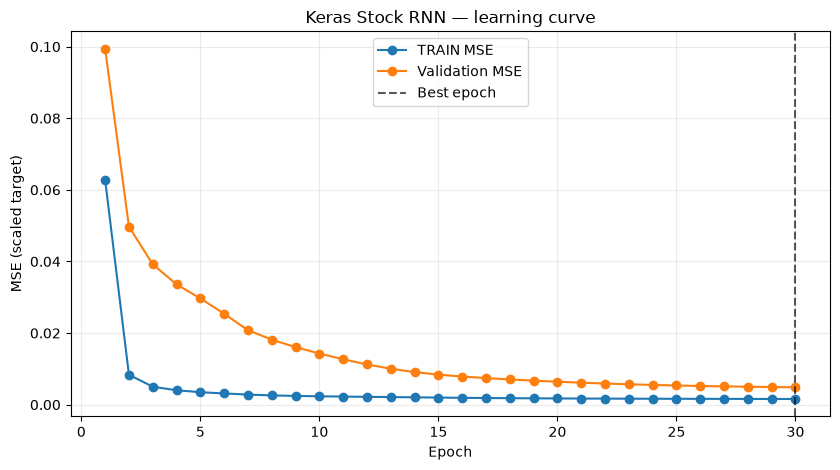

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'keras':
    epochs = np.arange(1, epochs_actually_run + 1)
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    ax.plot(epochs, history.history["loss"], marker="o", label="TRAIN MSE")
    ax.plot(epochs, history.history["val_loss"], marker="o", label="Validation MSE")
    ax.axvline(best_epoch, color="black", linestyle="--", alpha=0.65, label="Best epoch")
    ax.set(title="Keras Stock RNN — learning curve", xlabel="Epoch", ylabel="MSE (scaled target)")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    loss_figure_path = FIGURE_DIR / "training_validation_loss.png"
    fig.savefig(loss_figure_path, dpi=160, bbox_inches="tight")
    plt.show()

## 7. Prediction, inverse scaling và TEST một lần

`predict()` sinh target scaled. Prediction và nhãn scaled được inverse-transform bằng target scaler TRAIN-only trước khi tính metric:

- **MAE:** độ lớn sai số tuyệt đối trung bình, đơn vị USD.
- **RMSE:** căn của MSE, đơn vị USD và nhạy hơn với sai số lớn.
- **R²:** tỷ lệ biến thiên được giải thích so với mốc dự đoán trung bình; có thể âm.

Naive baseline dùng cùng đúng 410 mẫu TEST:

$$\widehat{Close}_{t+1}^{naive} = Close_t.$$

Một RNN không được xem là hữu ích chỉ vì sai số tuyệt đối có vẻ nhỏ; phải so trực tiếp với baseline persistence này.

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'keras':
    test_scaled_prediction = model.predict(
        artifacts["test"]["X"], batch_size=BATCH_SIZE, verbose=0
    ).ravel()
    test_actual = artifacts["test"]["y"].astype(np.float64)
    test_true_restored = inverse_transform_targets(target_scaler, artifacts["test"]["y_scaled"])
    test_prediction = inverse_transform_targets(target_scaler, test_scaled_prediction)
    test_naive = artifacts["test"]["naive_last_close"].astype(np.float64)

    np.testing.assert_allclose(test_true_restored, test_actual, rtol=1e-5, atol=1e-4)
    rnn_metrics = regression_metrics(test_actual, test_prediction)
    naive_metrics = regression_metrics(test_actual, test_naive)

    pd.DataFrame(
        [
            {"Mô hình": "Keras Vanilla RNN", "MAE (USD)": rnn_metrics["mae"], "RMSE (USD)": rnn_metrics["rmse"], "R²": rnn_metrics["r2"]},
            {"Mô hình": "Naive: last Close", "MAE (USD)": naive_metrics["mae"], "RMSE (USD)": naive_metrics["rmse"], "R²": naive_metrics["r2"]},
        ]
    ).set_index("Mô hình").round(4)

,MAE (USD),RMSE (USD),R²
Mô hình,,,
Keras Vanilla RNN,23.1947,27.8703,-0.4347
Naive: last Close,2.6177,3.8789,0.9722


In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'keras':
    if rnn_metrics["rmse"] < naive_metrics["rmse"]:
        comparison_message = "Keras RNN có RMSE thấp hơn naive trên TEST trong lần chạy đã khóa này."
    elif rnn_metrics["rmse"] > naive_metrics["rmse"]:
        comparison_message = "Naive có RMSE thấp hơn Keras RNN; không có bằng chứng để tuyên bố RNN tốt hơn baseline."
    else:
        comparison_message = "Keras RNN và naive có RMSE bằng nhau trong độ chính xác số hiện tại."
    print(comparison_message)

Naive có RMSE thấp hơn Keras RNN; không có bằng chứng để tuyên bố RNN tốt hơn baseline.


## 8. Lưu predictions và metadata thí nghiệm

CSV giữ một hàng cho mỗi ngày mục tiêu theo thứ tự thời gian và cùng schema với PyTorch. JSON ghi kiến trúc, training history, real-scale metrics, baseline metrics, target scaler và checksum nguồn để phép so sánh sau này có thể truy vết.

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'keras':
    test_dates = pd.to_datetime(artifacts["test"]["target_date"].astype(str))
    predictions = pd.DataFrame(
        {
            "target_date": test_dates.strftime("%Y-%m-%d"),
            "actual_close": test_actual,
            "predicted_close": test_prediction,
            "naive_close": test_naive,
        }
    )
    assert predictions["target_date"].is_monotonic_increasing
    assert not predictions.isna().any().any()
    predictions.to_csv(PREDICTIONS_PATH, index=False)

    model_hash = sha256(MODEL_PATH)
    predictions_hash = sha256(PREDICTIONS_PATH)
    metrics_payload = {
        "task": pytorch_metrics["task"],
        "framework": "Keras",
        "framework_versions": {"tensorflow": tf.__version__, "keras": keras.__version__},
        "architecture": {
            "recurrent_layer": "keras.layers.SimpleRNN",
            "input_size": 5,
            "sequence_length": 30,
            "hidden_units": HIDDEN_UNITS,
            "num_layers": 1,
            "activation": "tanh",
            "head": "Dense(1, activation='linear')",
        },
        "parameter_count": parameter_count,
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "loss": "MSE on scaled target",
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "min_delta": MIN_DELTA,
        "restore_best_weights": True,
        "epochs": epochs_actually_run,
        "epochs_actually_run": epochs_actually_run,
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "best_validation_loss_space": "standardized target",
        "device": device_label.lower(),
        "training_duration_seconds": training_duration_seconds,
        "selection_scope": "validation loss only; TEST unused until final evaluation",
        "training_history": {
            "train_loss": [float(value) for value in history.history["loss"]],
            "validation_loss": [float(value) for value in history.history["val_loss"]],
        },
        "MAE": rnn_metrics["mae"],
        "RMSE": rnn_metrics["rmse"],
        "R2": rnn_metrics["r2"],
        "naive_MAE": naive_metrics["mae"],
        "naive_RMSE": naive_metrics["rmse"],
        "naive_R2": naive_metrics["r2"],
        "test_metrics_real_scale": rnn_metrics,
        "naive_test_metrics_real_scale": naive_metrics,
        "real_scale_units": {"mae": "USD", "rmse": "USD", "r2": "unitless"},
        "test_evaluation_count": 1,
        "test_samples": len(predictions),
        "target_date_range": {"min": predictions["target_date"].iloc[0], "max": predictions["target_date"].iloc[-1]},
        "target_scaling": {
            "type": type(target_scaler).__name__,
            "fit_scope": target_scaler_info["fit_scope"],
            "path": target_scaler_info["path"],
            "sha256": target_scaler_info["sha256"],
            "inverse_transformed_for_final_metrics": True,
        },
        "input_artifact_sha256": artifact_hashes,
        "model": {"path": str(MODEL_PATH.relative_to(ROOT)).replace("\\", "/"), "sha256": model_hash},
        "predictions": {"path": str(PREDICTIONS_PATH.relative_to(ROOT)).replace("\\", "/"), "rows": len(predictions), "sha256": predictions_hash},
        "comparison": comparison_message,
    }
    METRICS_PATH.write_text(json.dumps(metrics_payload, ensure_ascii=False, indent=2), encoding="utf-8")

    print(f"Đã lưu model -> {MODEL_PATH.relative_to(ROOT)}")
    print(f"Đã lưu {len(predictions):,} predictions -> {PREDICTIONS_PATH.relative_to(ROOT)}")
    print(f"Đã lưu metrics -> {METRICS_PATH.relative_to(ROOT)}")
    predictions.head()

Đã lưu model -> models\keras\keras_stock_rnn_best.keras
Đã lưu 410 predictions -> results\predictions\keras_stock_predictions.csv
Đã lưu metrics -> results\metrics\keras_stock_metrics.json


,target_date,actual_close,predicted_close,naive_close
0,2024-05-14,187.429993,184.138525,186.279999
1,2024-05-15,189.720001,184.446649,187.429993
2,2024-05-16,189.839996,185.944296,189.720001
3,2024-05-17,189.869995,186.593139,189.839996
4,2024-05-20,191.039993,186.428741,189.869995


## 9. Actual và predicted theo thời gian

Các đường được vẽ theo `target_date` tăng dần trên cùng thang USD. Cả Keras RNN và naive đều dùng cùng target; biểu đồ không xáo trộn thời gian và không hàm ý khả năng sinh lời.

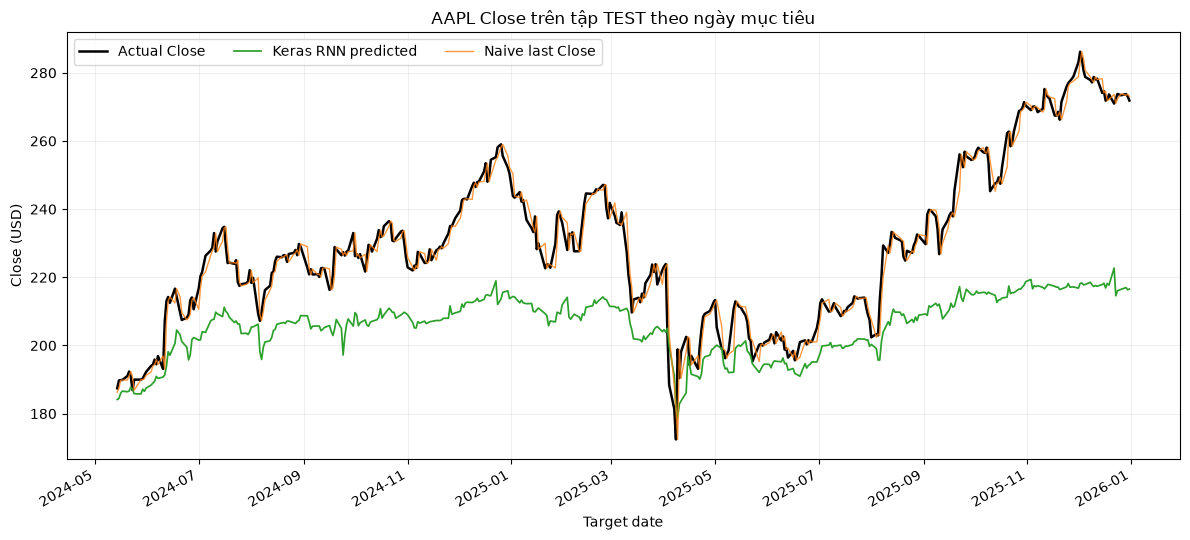

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'keras':
    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.plot(test_dates, test_actual, color="black", linewidth=1.8, label="Actual Close")
    ax.plot(test_dates, test_prediction, color="#2ca02c", linewidth=1.25, label="Keras RNN predicted")
    ax.plot(test_dates, test_naive, color="#ff7f0e", linewidth=1.0, alpha=0.8, label="Naive last Close")
    ax.set(title="AAPL Close trên tập TEST theo ngày mục tiêu", xlabel="Target date", ylabel="Close (USD)")
    ax.grid(alpha=0.2)
    ax.legend(ncol=3)
    fig.autofmt_xdate()
    fig.tight_layout()
    prediction_figure_path = FIGURE_DIR / "test_actual_vs_predicted.png"
    fig.savefig(prediction_figure_path, dpi=160, bbox_inches="tight")
    plt.show()

## 10. So sánh Keras RNN với naive baseline

MAE và RMSE được đặt cùng panel vì đều có đơn vị USD; R² nằm ở panel riêng vì không có đơn vị. Biểu đồ chỉ phản ánh 410 mẫu TEST đã khóa và không phải đánh giá đầu tư.

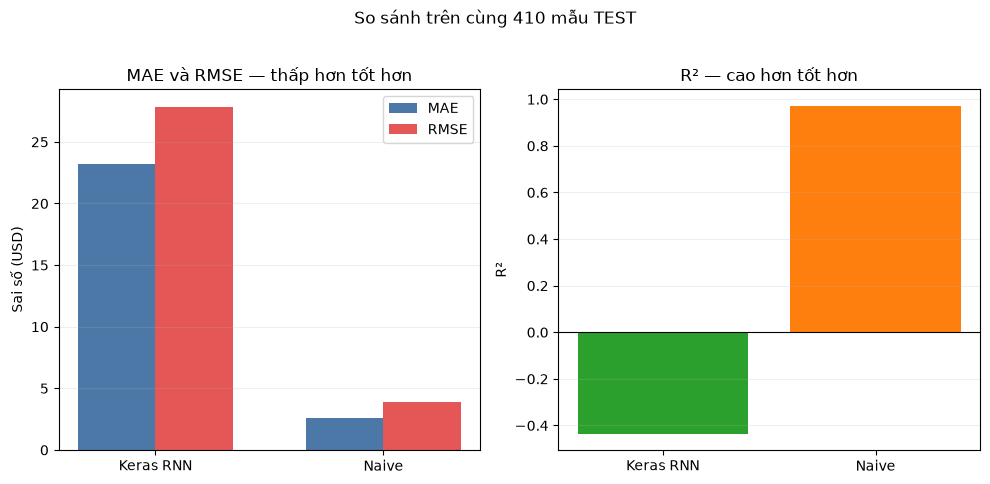

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'keras':
    labels = ["Keras RNN", "Naive"]
    colors = ["#2ca02c", "#ff7f0e"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.7))

    x = np.arange(2)
    width = 0.34
    axes[0].bar(x - width / 2, [rnn_metrics["mae"], naive_metrics["mae"]], width, label="MAE", color="#4c78a8")
    axes[0].bar(x + width / 2, [rnn_metrics["rmse"], naive_metrics["rmse"]], width, label="RMSE", color="#e45756")
    axes[0].set_xticks(x, labels)
    axes[0].set_ylabel("Sai số (USD)")
    axes[0].set_title("MAE và RMSE — thấp hơn tốt hơn")
    axes[0].legend()
    axes[0].grid(axis="y", alpha=0.2)

    axes[1].bar(labels, [rnn_metrics["r2"], naive_metrics["r2"]], color=colors)
    axes[1].axhline(0, color="black", linewidth=0.8)
    axes[1].set_ylabel("R²")
    axes[1].set_title("R² — cao hơn tốt hơn")
    axes[1].grid(axis="y", alpha=0.2)

    fig.suptitle("So sánh trên cùng 410 mẫu TEST", y=1.02)
    fig.tight_layout()
    comparison_figure_path = FIGURE_DIR / "rnn_vs_naive_metrics.png"
    fig.savefig(comparison_figure_path, dpi=160, bbox_inches="tight")
    plt.show()

## 11. Kiểm tra artifact đầu ra

Kiểm tra cuối xác nhận model nạp lại được, CSV đúng schema và thời gian, JSON có đủ metric, figures tồn tại, và checksum toàn bộ input/scaler vẫn giữ nguyên.

In [ ]:
if RUN_EXPERIMENTS and ACTIVE_FRAMEWORK == 'keras':
    expected_columns = ["target_date", "actual_close", "predicted_close", "naive_close"]
    assert MODEL_PATH.is_file()
    assert METRICS_PATH.is_file()
    assert PREDICTIONS_PATH.is_file()
    assert predictions.columns.tolist() == expected_columns
    assert len(predictions) == len(artifacts["test"]["y"]) == 410
    assert pd.to_datetime(predictions["target_date"]).is_monotonic_increasing
    assert not predictions["target_date"].duplicated().any()
    assert all(path.is_file() for path in (loss_figure_path, prediction_figure_path, comparison_figure_path))

    reloaded = keras.models.load_model(MODEL_PATH)
    assert reloaded.input_shape == (None, 30, 5)
    assert reloaded.output_shape == (None, 1)
    assert reloaded.count_params() == parameter_count

    saved_metrics = json.loads(METRICS_PATH.read_text(encoding="utf-8"))
    for key in ("MAE", "RMSE", "R2", "naive_MAE", "naive_RMSE", "naive_R2"):
        assert np.isfinite(saved_metrics[key])
    for split, expected_hash in artifact_hashes.items():
        input_path = ROOT / stock_meta["artifacts"][split]["path"]
        assert sha256(input_path) == expected_hash
    assert sha256(target_scaler_path) == target_scaler_info["sha256"]

    print("PASS — notebook chạy đầy đủ, model/CSV/JSON/figures hợp lệ, input và scaler không đổi.")
    print("Figures:", sorted(path.name for path in FIGURE_DIR.glob("*.png")))

PASS — notebook chạy đầy đủ, model/CSV/JSON/figures hợp lệ, input và scaler không đổi.
Figures: ['rnn_vs_naive_metrics.png', 'test_actual_vs_predicted.png', 'training_validation_loss.png']


## 12. Tóm tắt và giới hạn

- Keras dùng đúng input `(samples, 30, 5)`, target scaled, split và scaler của PyTorch.
- `SimpleRNN(64)` tạo hidden state cuối; `Dense(1)` tuyến tính tạo prediction regression.
- MSE huấn luyện nằm trong scaled space; MAE/RMSE chỉ mang đơn vị USD sau inverse scaling.
- Validation loss quyết định early stopping và model checkpoint; TEST chỉ được dự đoán một lần sau lựa chọn mô hình.
- Naive last-Close là mốc bắt buộc. Kết luận RNN tốt hơn hay kém hơn phải dựa trên metric thực tế, không dựa vào độ phức tạp.
- Giá cổ phiếu chịu ảnh hưởng bởi thông tin và thay đổi chế độ thị trường không được mô tả đầy đủ bởi 30 ngày OHLCV. Kết quả của một split lịch sử không bảo đảm hiệu quả trong tương lai.

Notebook này **không đưa ra khuyến nghị tài chính**. So sánh tổng hợp PyTorch–Keras được dành cho Notebook 08.

## Kết quả gốc để đối chiếu

Các file đã lưu được đọc nguyên trạng; không fit hoặc forward TEST mới.

In [ ]:
import json
import pandas as pd
from IPython.display import display
for _relative in ['A06/results/metrics/keras_customer_metrics.json', 'A06/results/metrics/keras_stock_metrics.json', 'A06/results/metrics/pytorch_customer_metrics.json', 'A06/results/metrics/pytorch_stock_metrics.json']:
    _path = REPO / _relative
    print(_relative)
    if _path.suffix == ".csv": display(pd.read_csv(_path))
    else: display(json.loads(_path.read_text()))


In [ ]:
import inspect
_notebook_defined = [(name, key) for name, mod in INLINE_MODULES.items() for key, obj in vars(mod).items() if inspect.isfunction(obj) and obj.__module__ == name]
assert all(vars(INLINE_MODULES[name])[key].__code__.co_filename.startswith("<notebook>/") for name,key in _notebook_defined)
print({"module có code ngay trong notebook": sum(bool(getattr(m,"__notebook_source__",False)) for m in INLINE_MODULES.values()), "hàm inline":len(_notebook_defined), "train/TEST đã chạy":False})
